<a href="https://colab.research.google.com/github/kimheeseo/LSCNS/blob/main/SEM_CNN_Drive_FolderLabels.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 광섬유 SEM CNN — Drive 증강·학습·검증·Grad-CAM

입력: https://drive.google.com/drive/folders/1atpGcoIZklOD6tY9VeymUFybTISE77M0

**실행 순서:** 원본 검사 → 폴더명 정답 자동 적용·시료 후보 자동 그룹화 → Train/Validation 시료별 분할 → Train 10배 증강 → Drive 저장·재로딩 → CNN 학습·검증 → 신규 사진 분류·Grad-CAM.

이 파일 안에 전체 Python 코드가 들어 있습니다. 별도 Google 문서, 설치용 노트북, 외부 공통 스크립트 파일을 불러오지 않습니다. 최초에는 의존성과 사전학습 가중치를 인터넷에서 내려받습니다.

Colab에서 **런타임 → 런타임 유형 변경 → GPU**를 선택하세요. Google 인증과 Drive 마운트는 같은 계정으로 진행합니다. 모델 학습 및 SEM 데이터 평가가 실행된 결과를 이 파일에 미리 넣지 않았습니다.

현재 알려진 입력은 PNG 583개이며, 실제 개수는 실행 시 다시 확인합니다. HCF는 구조 정보이며 정답 클래스는 Bending/Cleaving/Fracture 3종입니다.


In [1]:
%pip -q install pillow numpy pandas scipy scikit-learn imagehash matplotlib tqdm gradio ipywidgets


In [2]:
from google.colab import auth, drive
auth.authenticate_user()
drive.mount('/content/drive')

import json
from pathlib import Path
import google.auth
from googleapiclient.discovery import build
credentials, _ = google.auth.default()
drive_api = build('drive', 'v3', credentials=credentials, cache_discovery=False)

SOURCE_FOLDER_ID = '1atpGcoIZklOD6tY9VeymUFybTISE77M0'

def mounted_folder_path(folder_id):
    root_id = drive_api.files().get(fileId='root', fields='id').execute(num_retries=5)['id']
    current = folder_id
    parts = []
    visited = set()
    while current != root_id:
        if current in visited:
            raise RuntimeError('폴더 부모 경로에 순환이 있습니다.')
        visited.add(current)
        item = drive_api.files().get(
            fileId=current, fields='id,name,mimeType,parents,driveId',
            supportsAllDrives=True,
        ).execute(num_retries=5)
        if item.get('driveId'):
            raise RuntimeError('공유 드라이브인 경우 SOURCE_PATH를 마운트된 공유 드라이브 경로로 지정하세요.')
        if item['mimeType'] != 'application/vnd.google-apps.folder':
            raise RuntimeError('입력 ID가 폴더가 아닙니다.')
        parts.append(item['name'])
        parents = item.get('parents', [])
        if len(parents) != 1:
            raise RuntimeError('입력 폴더의 My Drive 경로를 확인할 수 없습니다. 같은 계정으로 인증하세요.')
        current = parents[0]
    result = Path('/content/drive/MyDrive').joinpath(*reversed(parts))
    if not result.is_dir():
        raise RuntimeError(f'마운트된 원본 폴더를 찾지 못했습니다: {result}')
    return result

SOURCE_PATH = mounted_folder_path(SOURCE_FOLDER_ID)
RESULTS_PATH = SOURCE_PATH.parent / 'SEM_CNN_Results' / 'Fiber_Category_PNG_FolderLabels'
IMAGE_SIZE = 384
EPOCHS = 3
USE_LOCAL_CACHE = True
print('원본 폴더:', SOURCE_PATH)
print('결과 폴더:', RESULTS_PATH)
print('이 노트북은 원본 PNG를 수정하거나 다시 변환하지 않습니다.')


Mounted at /content/drive
원본 폴더: /content/drive/MyDrive/Fiber Category_PNG
결과 폴더: /content/drive/MyDrive/SEM_CNN_Results/Fiber_Category_PNG_FolderLabels
이 노트북은 원본 PNG를 수정하거나 다시 변환하지 않습니다.


## 전체 Python 코드

아래 셀에는 검사·증강·학습·검증·추론·UI 함수가 모두 포함되어 있습니다.

In [3]:
"""광섬유 SEM PNG 데이터의 검토·증강·학습·검증·추론 파이프라인."""
from pathlib import Path
from collections import defaultdict
import os, io, json, hashlib, random, re, shutil, time, copy, threading
import tempfile, uuid
from datetime import datetime, timezone, timedelta
from zipfile import ZipFile, ZIP_DEFLATED
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
import imagehash
from scipy import ndimage
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix,
    ConfusionMatrixDisplay,
)
from tqdm.auto import tqdm

CLASSES = ["bending", "cleaving", "fracture"]
SEED = 42
AUG_NAMES = ["원본", "좌우 반전", "상하 반전", "90도 회전", "180도 회전",
             "270도 회전", "좌우 이동", "상하 이동", "1.1배 확대", "0.9배 축소"]

def digest(data):
    return hashlib.sha256(data).hexdigest()

def json_text(obj):
    return json.dumps(obj, ensure_ascii=False, indent=2, default=str)

def atomic(path, data, reuse=False):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if reuse and path.exists():
        if path.read_bytes() != data:
            raise RuntimeError(f"기존 파일의 내용이 다릅니다. 덮어쓰지 않았습니다: {path}")
        return
    temp = path.with_name(path.name + ".partial")
    temp.write_bytes(data)
    os.replace(temp, path)
    if path.read_bytes() != data:
        raise IOError(f"저장 재확인 실패: {path}")

def save_csv(path, frame):
    atomic(path, frame.to_csv(index=False, lineterminator="\n").encode("utf-8-sig"))

def read_csv(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False)

def is_true(value):
    return str(value).strip().lower() in {"true", "1", "yes", "approved", "예", "완료"}

def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def open_rgb(path):
    with Image.open(path) as im:
        if getattr(im, "n_frames", 1) != 1:
            raise ValueError("다중 프레임은 별도 검토가 필요합니다.")
        im.load()
        if im.mode.startswith("I;16") or im.mode in {"I", "F"}:
            arr = np.array(im, dtype=np.float64)
            if not np.isfinite(arr).all():
                raise ValueError("유효하지 않은 픽셀이 있습니다.")
            lo, hi = float(arr.min()), float(arr.max())
            arr = np.zeros(arr.shape, np.uint8) if hi <= lo else np.rint(
                (arr - lo) / (hi - lo) * 255
            ).clip(0,255).astype(np.uint8)
            return Image.fromarray(arr).convert("RGB")
        return im.convert("RGB").copy()

def png_bytes(im):
    out = io.BytesIO(); im.save(out, format="PNG"); return out.getvalue()

def propose_sem_footer(im):
    """하단의 청색 SEM 정보바만 보수적으로 검출합니다. 검출 자체는 승인이 아닙니다."""
    arr=np.asarray(im.convert("RGB"),dtype=np.int16)
    h,w=arr.shape[:2]
    if h<40 or w<80:
        return {"detected":False,"reason":"정보바 자동 검출에 해상도가 부족함","boxes":[]}
    x0=max(0,int(w*.02)); x1=max(x0+1,int(w*.98))
    sample=arr[:,x0:x1]
    blue=(sample[:,:,2]>sample[:,:,0]+20)&(sample[:,:,2]>sample[:,:,1]+5)&(sample[:,:,2]>60)
    rows=blue.mean(1)>.55
    # 정보바 안의 얇은 가로 구분선 때문에 밴드가 둘로 나뉘지 않도록 합니다.
    gaps,gap_count=ndimage.label(~rows)
    for index in range(1,gap_count+1):
        ys=np.flatnonzero(gaps==index)
        if ys[0]>0 and ys[-1]<h-1 and len(ys)<=max(2,int(h*.006)):
            rows[ys]=True
    labels,count=ndimage.label(rows)
    candidates=[]
    for index in range(1,count+1):
        ys=np.flatnonzero(labels==index)
        start,end=int(ys[0]),int(ys[-1])+1
        if start<h*.60 or end<h*.94 or end-start<max(5,int(h*.025)):
            continue
        if end-start>h*.30:
            continue
        region=sample[start:end]
        bright=(region.min(2)>150)
        ink=float(bright.mean())
        # 단순 청색 물체를 정보바로 취급하지 않도록 문자/구분선에 해당하는 밝은 픽셀도 요구합니다.
        if not .002<=ink<=.40:
            continue
        candidates.append((start,end,float(blue[start:end].mean()),ink))
    if not candidates:
        return {"detected":False,"reason":"청색 SEM 정보바 형식을 확정하지 못함","boxes":[]}
    start,end,coverage,ink=max(candidates,key=lambda item:item[1]-item[0])
    boxes=[[0,start,w,h]]
    # 흑백 SEM 영상 모서리의 녹색 일시정지 등 화면 표시도 제외 후보로 제안합니다.
    # 후보 미리보기 확인 전에는 실제 학습용 마스킹을 승인하지 않습니다.
    saturated=(arr.max(2)-arr.min(2)>60)&(arr.max(2)>80)
    saturated[start:]=False
    corner_w,corner_h=max(1,int(w*.20)),max(1,int(h*.20))
    for x0,y0,x1,y1 in [(0,0,corner_w,corner_h),(w-corner_w,0,w,corner_h),
                        (0,h-corner_h,corner_w,h),(w-corner_w,h-corner_h,w,h)]:
        ys,xs=np.where(saturated[y0:y1,x0:x1])
        if len(xs)<6: continue
        box=[max(0,x0+int(xs.min())-2),max(0,y0+int(ys.min())-2),
             min(w,x0+int(xs.max())+3),min(h,y0+int(ys.max())+3)]
        if (box[2]-box[0])*(box[3]-box[1])<=w*h*.025:
            boxes.append(box)
    return {"detected":True,"reason":"하단 청색 SEM 정보바 및 모서리 색상 표시 후보",
            "boxes":boxes,"start_y":start,"coverage":coverage,"ink_fraction":ink}

def footer_still_visible(roi, masks, footer):
    left,top=max(roi[0],footer[0]),max(roi[1],footer[1])
    right,bottom=min(roi[2],footer[2]),min(roi[3],footer[3])
    if left>=right or top>=bottom: return False
    covered=np.zeros((bottom-top,right-left),dtype=bool)
    for mask in masks:
        x0,y0=max(left,mask[0]),max(top,mask[1])
        x1,y1=min(right,mask[2]),min(bottom,mask[3])
        if x0<x1 and y0<y1: covered[y0-top:y1-top,x0-left:x1-left]=True
    return not bool(covered.all())

def parse_box(text, width, height):
    box = json.loads(str(text))
    if not isinstance(box, list) or len(box) != 4:
        raise ValueError("분석 영역은 [왼쪽, 위, 오른쪽, 아래] 형식입니다.")
    if not all(isinstance(v, int) and not isinstance(v, bool) for v in box):
        raise ValueError("영역 좌표는 정수여야 합니다.")
    x0,y0,x1,y1 = box
    if not (0 <= x0 < x1 <= width and 0 <= y0 < y1 <= height):
        raise ValueError("영역 좌표가 이미지 범위를 벗어납니다.")
    return box

def analysis_image(im, roi_text, masks_text):
    box = parse_box(roi_text, im.width, im.height)
    masks = json.loads(str(masks_text))
    if not isinstance(masks, list):
        raise ValueError("제외 영역은 사각형 목록이어야 합니다.")
    result = im.copy()
    draw = ImageDraw.Draw(result)
    for mask in masks:
        rect = parse_box(json.dumps(mask), im.width, im.height)
        # 오른쪽·아래 경계는 포함하지 않는 픽셀 좌표 규칙을 사용합니다.
        draw.rectangle([rect[0],rect[1],rect[2]-1,rect[3]-1], fill=(0,0,0))
    return result.crop(box), box

def variants(im):
    """ROI 전체를 보존하는 공통 캔버스. 모든 분할의 000도 같은 전처리."""
    w,h = im.size
    side = int(np.ceil(max(w,h)*1.35))+4
    direction=hashlib.sha256(np.asarray(im).tobytes()).digest()[0]
    moved_x=max(1,round(w*.05))*(1 if direction&1 else -1)
    moved_y=max(1,round(h*.05))*(1 if direction&2 else -1)
    images = [
        (im,0,0), (ImageOps.mirror(im),0,0), (ImageOps.flip(im),0,0),
        (im.transpose(Image.Transpose.ROTATE_90),0,0),
        (im.transpose(Image.Transpose.ROTATE_180),0,0),
        (im.transpose(Image.Transpose.ROTATE_270),0,0),
        (im,moved_x,0), (im,0,moved_y),
        (im.resize((max(1,round(w*1.1)),max(1,round(h*1.1))),Image.Resampling.LANCZOS),0,0),
        (im.resize((max(1,round(w*.9)),max(1,round(h*.9))),Image.Resampling.LANCZOS),0,0),
    ]
    for number,(version,dx,dy) in enumerate(images):
        left=(side-version.width)//2+dx; top=(side-version.height)//2+dy
        if not (left>=0 and top>=0 and left+version.width<=side and top+version.height<=side):
            raise RuntimeError("증강 중 ROI가 잘리는 설정입니다.")
        canvas=Image.new("RGB",(side,side),(0,0,0))
        canvas.paste(version,(left,top))
        yield number,canvas

class SavedDataset(Dataset):
    def __init__(self, frame, image_size=384):
        self.frame=frame.reset_index(drop=True)
        self.transform=transforms.Compose([
            transforms.Resize((image_size,image_size)),
            transforms.ToTensor(),
            transforms.Normalize([.485,.456,.406],[.229,.224,.225]),
        ])
    def __len__(self): return len(self.frame)
    def __getitem__(self,index):
        row=self.frame.iloc[index]
        return self.transform(open_rgb(row["load_path"])), int(row["class_id"]), index

class Pipeline:
    def __init__(self, source, root, image_size=384, folder_labels=True):
        self.source=Path(source).resolve()
        self.root=Path(root).resolve()
        if not self.source.is_dir():
            raise RuntimeError(f"원본 폴더가 없습니다: {self.source}")
        if self.source==self.root or self.source in self.root.parents:
            raise RuntimeError("결과 폴더를 원본 안에 만들 수 없습니다.")
        self.folder_labels=bool(folder_labels)
        self.image_size=int(image_size)
        self.manifest=self.root/"01_Dataset_Manifest"
        self.data=self.root/"02_Augmented_Dataset"
        self.models=self.root/"03_Models"
        self.reports=self.root/"04_Training_Reports"
        self.predictions=self.root/"05_Predictions"
        for p in [self.manifest,self.data,self.models,self.reports,self.predictions,self.root/"06_Notebooks"]:
            p.mkdir(parents=True,exist_ok=True)
        self.predict_lock=threading.RLock()

    def inspect_dataset(self):
        mapping_path=self.source/"rename_mapping.csv"
        lookup={}
        if mapping_path.exists():
            mapping=pd.read_csv(mapping_path,encoding="utf-8-sig",dtype=str).fillna("")
            if {"원본 경로","새 경로"}.issubset(mapping.columns):
                normalized=mapping["새 경로"].str.replace("\\","/",regex=False)
                lookup=dict(zip(normalized,mapping["원본 경로"].str.replace("\\","/",regex=False)))
        # 대응표는 출처·동일 시료 후보를 위한 보조 정보이며 정답은 현재 폴더에서 읽습니다.
        rows=[]; failures=[]; exact=defaultdict(list); stems=defaultdict(list)
        for path in tqdm(sorted(p for p in self.source.rglob("*") if p.is_file() and p.suffix.lower()==".png"),desc="원본 검사",unit="개"):
            rel=path.relative_to(self.source).as_posix()
            try:
                label=rel.split("/")[0].lower()
                if label not in CLASSES: raise ValueError("클래스 폴더 불명")
                original=lookup.get(rel,rel)
                raw=path.read_bytes()
                with Image.open(io.BytesIO(raw)) as native:
                    if native.format!="PNG": raise ValueError("실제 PNG 형식이 아님")
                    native.load()
                    metadata=json_text({"mode":native.mode,"info":native.info})
                im=open_rgb(path); arr=np.asarray(im)
                pixel=digest(str(im.size).encode()+arr.tobytes())
                image_id=digest(rel.encode())[:20]
                hcf="HCF" if "HCF" in [part.upper() for part in Path(rel).parts[:-1]] or "/HCF/" in "/"+original.upper()+"/" or "_HCF_" in path.name.upper() else "non_HCF"
                stem=Path(original).stem
                candidate=re.sub(r"\s*\(\d+\)\s*$","",stem)
                candidate=re.sub(r"(?i)(^|[_ -])(SE|BSE)(?=$|[_ -])","_",candidate)
                candidate=re.sub(r"(?i)(^|[_ -])x\d+","_",candidate)
                candidate=re.sub(r"[_ -]\d+$","",candidate).strip("_ -").lower()
                suggested="candidate_"+digest((hcf+"|"+candidate if rel in lookup else "unmapped|"+rel).encode())[:12]
                detector=re.search(r"(?i)(?:^|[_ -])(BSE|SE)(?:$|[_ -])",stem)
                row={
                    "image_id":image_id,"source_path":str(path),"relative_path":rel,
                    "original_path":original,"original_filename":Path(original).name,
                    "current_filename":path.name,"class_name":label,"class_id":CLASSES.index(label),
                    "fiber_type":hcf,"source_sha256":digest(raw),"pixel_sha256":pixel,
                    "phash":str(imagehash.phash(im)),"width":im.width,"height":im.height,
                    "detector":detector.group(1).upper() if detector else "",
                    "suggested_specimen_id":suggested,"metadata_json":metadata,
                }
                rows.append(row); exact[pixel].append(image_id); stems[suggested].append(image_id)
            except Exception as exc:
                failures.append({"relative_path":rel,"error":str(exc)})
        save_csv(self.manifest/"decode_errors.csv",pd.DataFrame(failures,columns=["relative_path","error"]))
        if failures: raise RuntimeError("원본 디코딩 실패가 있습니다. decode_errors.csv를 확인하세요.")
        if not rows: raise RuntimeError("PNG 이미지가 없습니다.")
        frame=pd.DataFrame(rows)
        fingerprint=digest("\n".join(sorted(frame["relative_path"]+"|"+frame["source_sha256"])).encode())
        config_path=self.root/"project.json"
        if config_path.exists() and json.loads(config_path.read_text())["source_fingerprint"]!=fingerprint:
            raise RuntimeError("원본 구성이 변경됐습니다. 별도 프로젝트를 사용하세요.")
        atomic(config_path,json_text({"source":str(self.source),"source_fingerprint":fingerprint,
            "source_count":len(frame),"seed":SEED,"image_size":self.image_size}).encode())
        save_csv(self.manifest/"original_manifest.csv",frame)
        review=[]
        def add(kind, members):
            if len(members)>1:
                group=digest((kind+"|"+",".join(sorted(members))).encode())[:16]
                review.extend({"review_group":group,"reason":kind,"image_id":m} for m in members)
        for members in exact.values(): add("동일 픽셀",members)
        for members in stems.values(): add("원본 이름 기반 동일 시료 후보",members)
        hashes=[int(v,16) for v in frame["phash"]]
        for i in range(len(frame)):
            for j in range(i+1,len(frame)):
                distance=(hashes[i]^hashes[j]).bit_count()
                if distance<=6 and frame.iloc[i]["pixel_sha256"]!=frame.iloc[j]["pixel_sha256"]:
                    add(f"지각 해시 유사도 후보 거리 {distance}",[frame.iloc[i]["image_id"],frame.iloc[j]["image_id"]])
        save_csv(self.manifest/"label_review.csv",pd.DataFrame(review,columns=["review_group","reason","image_id"]))
        group_path=self.manifest/"specimen_groups.csv"
        if not group_path.exists():
            groups=frame[["image_id","current_filename","original_path"]].copy()
            groups["specimen_id"]=frame["suggested_specimen_id"]
            groups["class_name"]=frame["class_name"]
            groups["approved"]=False; groups["excluded"]=False
            groups["roi"]=[json.dumps([0,0,int(w),int(h)]) for w,h in zip(frame.width,frame.height)]
            groups["mask_boxes"]="[]"
            groups["reviewer_notes"]=""
            save_csv(group_path,groups)
        else:
            groups=read_csv(group_path)
            if set(groups["image_id"])!=set(frame["image_id"]):
                raise RuntimeError("기존 시료 검토표와 현재 원본 목록이 다릅니다.")
        print(f"PNG {len(frame)}개. 원본 이름·동일 픽셀·지각 해시 후보를 기록했습니다.")
        if self.folder_labels:
            self.apply_folder_labels(frame)
            print("폴더명을 정답으로 적용했습니다. 사진별 라벨 승인 없이 증강·학습할 수 있습니다.")
        else:
            print("선택적 수동 검토 모드입니다.")
        return frame.groupby(["class_name","fiber_type"]).size().reset_index(name="원본 수")

    def apply_folder_labels(self, frame=None):
        """현재 폴더 정답을 고정하고 후보 그룹·정보바를 승인 없이 자동 처리합니다."""
        if frame is None: frame=read_csv(self.manifest/"original_manifest.csv")
        parents={str(v):str(v) for v in frame.image_id}
        def find(v):
            while parents[v]!=v:
                parents[v]=parents[parents[v]]; v=parents[v]
            return v
        def union(ids):
            ids=list(map(str,ids))
            for v in ids[1:]:
                a,b=find(ids[0]),find(v)
                parents[max(a,b)]=min(a,b)
        # 동일 픽셀·원본 이름 계열·강한 유사도 후보는 같은 분할에 둡니다.
        for column in ["pixel_sha256","suggested_specimen_id"]:
            for _,part in frame.groupby(column): union(part.image_id)
        candidates=read_csv(self.manifest/"label_review.csv")
        if len(candidates):
            for _,part in candidates.groupby("review_group"): union(part.image_id)
        groups=[]; preprocessing=[]
        for row in frame.itertuples(index=False):
            footer=propose_sem_footer(open_rgb(row.source_path))
            specimen="auto_"+digest(find(str(row.image_id)).encode())[:12]
            groups.append({"image_id":row.image_id,"current_filename":row.current_filename,
                "original_path":row.original_path,"specimen_id":specimen,
                "class_name":row.class_name,"approved":True,"excluded":False,
                "roi":json.dumps([0,0,int(row.width),int(row.height)]),
                "mask_boxes":json.dumps(footer["boxes"]),
                "reviewer_notes":"정답=현재 클래스 폴더. 자동 후보 그룹이며 실제 시료 동일성 확정은 아님."})
            preprocessing.append({"image_id":row.image_id,"class_name":row.class_name,
                "footer_detected":footer["detected"],"preprocessing_note":footer["reason"]})
        save_csv(self.manifest/"specimen_groups.csv",pd.DataFrame(groups))
        save_csv(self.manifest/"automatic_preprocessing.csv",pd.DataFrame(preprocessing))
        collisions=frame[frame.groupby("pixel_sha256")["class_name"].transform("nunique")>1]
        save_csv(self.manifest/"cross_folder_duplicates.csv",collisions)
        atomic(self.manifest/"label_policy.json",json_text({"labels":"current_class_folder",
            "manual_approval_required":False,"cross_folder_duplicates":"keep_folder_labels_same_split",
            "grouping_limit":"자동 후보 그룹은 물리적 시료 식별을 보장하지 않음",
            "footer_limit":"자동 인식한 정보바만 제외. 미검출 정보바가 남을 수 있음"}).encode())
        return pd.DataFrame(groups)

    def prepare_batch_review(self):
        """시료 그룹/하단 정보바 후보를 제안합니다. 개별·일괄 승인은 별도 사용자 동작입니다."""
        marker=self.data/"dataset_status.json"
        if marker.exists() and json.loads(marker.read_text()).get("state")=="complete":
            print("증강 완료 데이터가 있어 기존 검토를 변경하지 않습니다. 저장 데이터 재사용 또는 학습을 진행하세요.")
            summary_path=self.manifest/"batch_review_summary.csv"
            return read_csv(summary_path) if summary_path.exists() else pd.DataFrame({"상태":["기존 증강 완료 데이터 유지"]})
        source=read_csv(self.manifest/"original_manifest.csv").set_index("image_id")
        groups=self.review_table().set_index("image_id")
        if set(source.index)!=set(groups.index):
            raise RuntimeError("원본 목록과 시료 검토표가 다릅니다.")
        parent={key:key for key in source.index}
        def find(key):
            while parent[key]!=key:
                parent[key]=parent[parent[key]]; key=parent[key]
            return key
        def union(a,b):
            a,b=find(a),find(b)
            if a!=b:
                parent[max(a,b)]=min(a,b)
        # 같은 원본 이름 계열과 동일 픽셀은 보수적인 분할 블록 후보로 묶습니다.
        # 실제 물리 시료가 같다고 자동 확정하는 것은 아닙니다.
        for column in ["suggested_specimen_id","pixel_sha256"]:
            for _,part in source.groupby(column):
                ids=list(part.index)
                for key in ids[1:]: union(ids[0],key)
        components=defaultdict(list)
        for key in source.index: components[find(key)].append(key)
        component_for={key:find(key) for key in source.index}
        conflicts=set()
        for _,part in source.groupby("pixel_sha256"):
            labels={str(groups.loc[key,"class_name"]) for key in part.index}
            if len(labels)>1:
                conflicts.update(component_for[key] for key in part.index)
        visual_ambiguity=set()
        review_path=self.manifest/"label_review.csv"
        if review_path.exists():
            pairs=read_csv(review_path)
            for _,part in pairs.groupby("review_group"):
                reason=str(part.iloc[0].reason)
                match=re.search(r"지각 해시 유사도 후보 거리 (\d+)",reason)
                ids=[key for key in part.image_id if key in component_for]
                if match and int(match.group(1))<=2 and len({component_for[key] for key in ids})>1:
                    visual_ambiguity.update(component_for[key] for key in ids)
        proposed_ids={}; component_reasons={}
        for key,ids in components.items():
            approved_ids={str(groups.loc[i,"specimen_id"]) for i in ids if is_true(groups.loc[i,"approved"])}
            reasons=[]
            if key in conflicts: reasons.append("동일 픽셀의 라벨 충돌")
            if key in visual_ambiguity: reasons.append("다른 시료 그룹과 매우 유사한 이미지")
            if len(approved_ids)>1: reasons.append("기존 승인 시료 ID가 여러 개임")
            if len(ids)>max(12,int(len(source)*.30)): reasons.append("후보 그룹이 지나치게 커서 병합 범위 검토 필요")
            stems=[Path(str(source.loc[i,"original_filename"])).stem.lower() for i in ids]
            generic=lambda value: bool(re.fullmatch(r"(?:\d+|capture\d*|image\d*|img\d*|[a-z]{1,8}\d*)",value))
            if all(generic(value) for value in stems): reasons.append("원본 이름만으로 시료 추적이 어려움")
            proposed_ids[key]=next(iter(approved_ids)) if len(approved_ids)==1 else "batch_"+digest("|".join(sorted(ids)).encode())[:12]
            component_reasons[key]=reasons
        for column in ["auto_specimen_id","auto_mask_boxes","auto_ready","auto_group_ready","auto_reason","auto_group_size"]:
            groups[column]=""
        for image_id,row in tqdm(source.iterrows(),total=len(source),desc="그룹·정보바 일괄 후보 생성"):
            key=component_for[image_id]
            groups.loc[image_id,"auto_specimen_id"]=proposed_ids[key]
            groups.loc[image_id,"auto_group_size"]=len(components[key])
            groups.loc[image_id,"auto_ready"]=False
            groups.loc[image_id,"auto_group_ready"]=False
            if is_true(groups.loc[image_id,"excluded"]):
                groups.loc[image_id,"auto_reason"]="기존 학습 제외 유지"; continue
            im=open_rgb(row.source_path)
            footer=propose_sem_footer(im)
            was_approved=is_true(groups.loc[image_id,"approved"])
            current_roi=json.loads(str(groups.loc[image_id,"roi"]))
            current_masks=json.loads(str(groups.loc[image_id,"mask_boxes"]))
            reopened=was_approved and footer["detected"] and any(footer_still_visible(current_roi,current_masks,box) for box in footer["boxes"])
            if was_approved and not reopened:
                groups.loc[image_id,"auto_reason"]="기존 개별 검토 결과 유지"; continue
            if reopened:
                groups.loc[image_id,"approved"]=False
                groups.loc[image_id,"reviewer_notes"]=(str(groups.loc[image_id,"reviewer_notes"])+" | 기존 승인 영역에 청색 정보바가 남아 재검토 후보로 전환").strip(" |")
            reasons=list(component_reasons[key])
            full_box=[0,0,int(row.width),int(row.height)]
            current_specimen=str(groups.loc[image_id,"specimen_id"])
            if not reopened and (current_roi!=full_box or current_masks or not current_specimen.startswith("candidate_")):
                reasons.append("이미 개별 편집 중인 항목이므로 자동 변경하지 않음")
            groups.loc[image_id,"auto_group_ready"]=not reasons
            proposed_masks=list(current_masks)
            for box in footer["boxes"]:
                if box not in proposed_masks: proposed_masks.append(box)
            groups.loc[image_id,"auto_mask_boxes"]=json.dumps(proposed_masks)
            if not footer["detected"]: reasons.append(footer["reason"])
            groups.loc[image_id,"auto_ready"]=not reasons
            groups.loc[image_id,"auto_reason"]="; ".join(reasons) if reasons else ("기존 승인에 남은 정보바를 제외하는 후보 — 일괄 확인 대기" if reopened else "자동 검사 통과 후보 — 그룹·영역 일괄 확인 대기")
        save_csv(self.manifest/"specimen_groups.csv",groups.reset_index())
        summary=[]
        for group_id,part in groups.groupby("auto_specimen_id"):
            ids=list(part.index)
            summary.append({"후보 시료 그룹":group_id,"사진 수":len(part),
                "클래스":", ".join(sorted(set(part.class_name))),
                "원본 이름 예":", ".join(str(source.loc[i,"original_filename"]) for i in ids[:3]),
                "일괄 확인 가능":int(part.auto_ready.map(is_true).sum()),
                "개별 검토 필요":int((~part.approved.map(is_true)&~part.excluded.map(is_true)&~part.auto_ready.map(is_true)).sum()),
                "검토 사유":" / ".join(sorted(set(part.auto_reason))),})
        summary=pd.DataFrame(summary)
        save_csv(self.manifest/"batch_review_summary.csv",summary)
        ready=groups[groups.auto_ready.map(is_true)]
        # 클래스·구조·후보 그룹이 겹치지 않는 대표 샘플을 우선 표시합니다.
        sample_ids=[]; seen=set()
        for image_id,row in ready.iterrows():
            key=(row.class_name,source.loc[image_id,"fiber_type"],row.auto_specimen_id)
            if key not in seen:
                sample_ids.append(image_id); seen.add(key)
            if len(sample_ids)>=12: break
        if sample_ids:
            tile_w,tile_h=300,250; columns=4
            sheet=Image.new("RGB",(tile_w*columns,tile_h*((len(sample_ids)+columns-1)//columns)),"white")
            for index,image_id in enumerate(sample_ids):
                row=source.loc[image_id]; preview=open_rgb(row.source_path)
                draw=ImageDraw.Draw(preview)
                for box in json.loads(groups.loc[image_id,"auto_mask_boxes"]):
                    draw.rectangle([box[0],box[1],box[2]-1,box[3]-1],fill=(90,90,90))
                preview.thumbnail((tile_w-8,tile_h-35))
                x=(index%columns)*tile_w; y=(index//columns)*tile_h
                sheet.paste(preview,(x+4,y+4))
                ImageDraw.Draw(sheet).text((x+4,y+tile_h-25),str(row.current_filename)[:35],fill="black")
            atomic(self.reports/"batch_review_samples.png",png_bytes(sheet))
        elif (self.reports/"batch_review_samples.png").exists():
            (self.reports/"batch_review_samples.png").unlink()
        pending=groups[~groups.approved.map(is_true)&~groups.excluded.map(is_true)]
        print(f"미확정 {len(pending)}개 중 일괄 확인 후보 {len(ready)}개, 개별 예외 {len(pending)-len(ready)}개")
        print("자동 검출은 제안이며 승인하지 않았습니다. 그룹 요약·회색 정보바 제외 샘플을 확인하세요.")
        return summary

    def approve_batch_review(self, groups_confirmed=False, regions_confirmed=False):
        marker=self.data/"dataset_status.json"
        if marker.exists() and json.loads(marker.read_text()).get("state")=="complete":
            return "이미 증강 완료 상태입니다. 기존 검토를 변경하지 않고 저장 데이터·모델을 재사용하세요."
        if not is_true(groups_confirmed) or not is_true(regions_confirmed):
            raise RuntimeError("후보 시료 그룹 요약과 정보바 제외 샘플을 확인한 뒤 두 확인 항목을 선택하세요.")
        groups=self.review_table()
        if "auto_ready" not in groups:
            raise RuntimeError("먼저 자동 검토 후보를 생성하세요.")
        selected=groups.auto_ready.map(is_true)&~groups.approved.map(is_true)&~groups.excluded.map(is_true)
        group_selected=groups.auto_group_ready.map(is_true)&~groups.approved.map(is_true)&~groups.excluded.map(is_true)
        for i in groups.index[group_selected]:
            groups.loc[i,"specimen_id"]=str(groups.loc[i,"auto_specimen_id"])
        for i in groups.index[selected]:
            groups.loc[i,"specimen_id"]=str(groups.loc[i,"auto_specimen_id"])
            groups.loc[i,"mask_boxes"]=str(groups.loc[i,"auto_mask_boxes"])
            groups.loc[i,"approved"]=True
            groups.loc[i,"reviewer_notes"]=(str(groups.loc[i,"reviewer_notes"])+" | 그룹 요약·청색 정보바 제외 샘플을 확인하여 일괄 적용").strip(" |")
        self.save_review(groups)
        remaining=groups[~groups.approved.map(is_true)&~groups.excluded.map(is_true)]
        save_csv(self.manifest/"remaining_review.csv",remaining)
        return f"시료 그룹 {int(group_selected.sum())}개 이미지에 적용, 정보바 포함 검토 {int(selected.sum())}개 일괄 완료. 남은 개별 검토: {len(remaining)}개."

    def save_review(self, edited):
        original=read_csv(self.manifest/"original_manifest.csv")
        previous=read_csv(self.manifest/"specimen_groups.csv")
        edited=pd.DataFrame(edited).copy().fillna("")
        if edited["image_id"].duplicated().any() or set(edited["image_id"])!=set(original["image_id"]):
            raise ValueError("image_id를 추가·삭제·변경할 수 없습니다.")
        for _,row in edited.iterrows():
            if is_true(row["excluded"]): continue
            source=original.set_index("image_id").loc[row["image_id"]]
            if str(row["class_name"]) not in CLASSES: raise ValueError("클래스는 세 가지 중 하나여야 합니다.")
            if not str(row["specimen_id"]).strip(): raise ValueError("specimen_id가 비어 있습니다.")
            parse_box(row["roi"],int(source["width"]),int(source["height"]))
            for box in json.loads(str(row["mask_boxes"])):
                parse_box(json.dumps(box),int(source["width"]),int(source["height"]))
        save_csv(self.manifest/"specimen_groups.csv",edited[previous.columns])
        return "시료·라벨·영역 검토표를 Drive에 저장했습니다."

    def approved_data(self):
        if not (self.manifest/"original_manifest.csv").exists(): self.inspect_dataset()
        frame=read_csv(self.manifest/"original_manifest.csv")
        if self.folder_labels and not (self.manifest/"label_policy.json").exists(): self.apply_folder_labels(frame)
        review=read_csv(self.manifest/"specimen_groups.csv")
        if self.folder_labels:
            authoritative=frame.set_index("image_id")["class_name"]
            review["class_name"]=review.image_id.map(authoritative)
            review["approved"]=True; review["excluded"]=False
        frame=frame.drop(columns=["class_name","class_id"]).merge(
            review[["image_id","specimen_id","class_name","approved","excluded","roi","mask_boxes"]],
            on="image_id",validate="one_to_one")
        frame=frame[~frame["excluded"].map(is_true)].copy()
        if frame.empty: raise RuntimeError("사용 가능한 원본이 없습니다.")
        pending=frame[~frame["approved"].map(is_true)]
        if len(pending):
            raise RuntimeError(f"{len(pending)}개 원본의 시료·라벨·분석 영역 검토가 미완료입니다.")
        if frame["specimen_id"].str.strip().eq("").any(): raise RuntimeError("시료 ID가 비어 있습니다.")
        frame["class_id"]=frame["class_name"].map({v:i for i,v in enumerate(CLASSES)})
        if frame["class_id"].isna().any(): raise RuntimeError("잘못된 라벨이 있습니다.")
        if not self.folder_labels and frame.groupby("pixel_sha256")["class_name"].nunique().gt(1).any():
            raise RuntimeError("동일 픽셀 이미지의 라벨 충돌을 먼저 해결해야 합니다.")
        # 같은 픽셀을 가진 파일에 서로 다른 시료 ID를 부여한 경우 누출 위험을 막습니다.
        if frame.groupby("pixel_sha256")["specimen_id"].nunique().gt(1).any():
            raise RuntimeError("동일 픽셀 파일은 같은 specimen_id로 통합해야 합니다.")
        return frame.reset_index(drop=True)

    def choose_split(self, frame):
        counts=frame[["class_name","specimen_id"]].drop_duplicates().groupby("class_name").size()
        if set(counts.index)!=set(CLASSES) or counts.min()<2:
            raise RuntimeError("세 클래스 각각 최소 2개의 독립 시료가 필요합니다.")
        if counts.min()>=5:
            splitter=StratifiedGroupKFold(5,shuffle=True,random_state=SEED)
            candidates=splitter.split(frame,frame.class_name,frame.specimen_id)
        else:
            print("독립 시료가 적어 그룹 분할 후보를 탐색합니다. 추가 교차검증이 필요합니다.")
            splitter=GroupShuffleSplit(n_splits=1000,test_size=.2,random_state=SEED)
            candidates=splitter.split(frame,groups=frame.specimen_id)
        best=None
        for tr,va in candidates:
            a,b=frame.iloc[tr],frame.iloc[va]
            if set(a.class_name)!=set(CLASSES) or set(b.class_name)!=set(CLASSES): continue
            ratios=b.class_name.value_counts()/frame.class_name.value_counts()
            score=float(abs(ratios-.2).mean())+abs(len(b)/len(frame)-.2)
            if best is None or score<best[0]: best=(score,tr,va)
        if best is None: raise RuntimeError("클래스가 유지되는 그룹 분할을 찾지 못했습니다.")
        return best[1],best[2]

    def augment(self, split_override=None):
        frame=self.approved_data()
        if split_override is None:
            tr,va=self.choose_split(frame)
        else:
            tr,va=split_override
        frame["split"]=""
        frame.loc[tr,"split"]="train"; frame.loc[va,"split"]="validation"
        if frame["split"].eq("").any(): raise RuntimeError("분할되지 않은 원본이 있습니다.")
        a,b=frame[frame.split=="train"],frame[frame.split=="validation"]
        if set(a.specimen_id)&set(b.specimen_id): raise RuntimeError("동일 시료 분할 누출")
        if set(a.pixel_sha256)&set(b.pixel_sha256): raise RuntimeError("동일 픽셀 분할 누출")
        plan=[]
        for _,r in frame.iterrows():
            # 현재 파일명은 이미 클래스 접두어를 가지므로 접두어 중복을 피합니다.
            stem=Path(r.current_filename).stem
            if not stem.lower().startswith(r.class_name+"_"): stem=r.class_name+"_"+stem
            for number in (range(10) if r.split=="train" else [0]):
                plan.append((r.image_id,r.split,r.class_name,f"{stem}_{number:03d}.png",number))
        names=[(x[1],x[2],x[3]) for x in plan]
        if len(names)!=len(set(names)): raise RuntimeError("증강 파일명 충돌")
        signature=digest(json_text({
            "review":frame[["image_id","source_sha256","specimen_id","class_name","roi","mask_boxes","split"]].to_dict("records"),
            "augmentation":"10_versions_padding_1.35_v1"
        }).encode())
        marker=self.data/"dataset_status.json"
        if marker.exists():
            previous_status=json.loads(marker.read_text())
            if previous_status["signature"]!=signature:
                raise RuntimeError("기존 증강 데이터의 시료·분할·영역 설정과 다릅니다. 새 프로젝트를 사용하세요.")
            if previous_status["state"]=="complete":
                verified=self.verify_saved(use_cache=False)
                print("기존 Drive 증강 데이터를 재검증하여 재사용합니다.")
                return verified.groupby(["split","class_name"]).size().reset_index(name="저장·재로딩 검증 수")
        atomic(marker,json_text({"state":"running","signature":signature}).encode())
        expected={(s,c):set() for s in ["train","validation"] for c in CLASSES}
        for _,s,c,name,_ in plan: expected[(s,c)].add(name)
        for (s,c),wanted in expected.items():
            target=self.data/s/c; target.mkdir(parents=True,exist_ok=True)
            if {p.name for p in target.glob("*.png")}-wanted:
                raise RuntimeError(f"예상 밖 PNG가 있습니다: {target}")
        save_csv(self.manifest/"train_split.csv",a)
        save_csv(self.manifest/"validation_split.csv",b)
        records=[]; failures=[]; total=len(plan); done=0; bucket=-1
        for _,r in tqdm(frame.iterrows(),total=len(frame),desc="증강 및 Drive 저장",unit="원본"):
            try:
                if digest(Path(r.source_path).read_bytes())!=r.source_sha256:
                    raise RuntimeError("검사 이후 원본 내용이 변경됐습니다.")
                im,_=analysis_image(open_rgb(r.source_path),r.roi,r.mask_boxes)
                for number,version in variants(im):
                    if r.split=="validation" and number>0: break
                    name=next(x[3] for x in plan if x[0]==r.image_id and x[4]==number)
                    path=self.data/r.split/r.class_name/name
                    payload=png_bytes(version)
                    last=None
                    for attempt in range(3):
                        try:
                            atomic(path,payload,reuse=True)
                            # 반드시 Drive 저장 파일에서 다시 읽습니다.
                            saved=path.read_bytes()
                            with Image.open(io.BytesIO(saved)) as check:
                                check.load()
                                if check.format!="PNG" or not np.array_equal(np.array(check),np.array(version)):
                                    raise RuntimeError("저장 이미지 PNG·픽셀 검증 실패")
                            last=None; break
                        except Exception as exc:
                            last=exc; time.sleep(attempt+1)
                    if last is not None: raise last
                    records.append({
                        "image_id":r.image_id,"specimen_id":r.specimen_id,
                        "class_name":r.class_name,"class_id":int(r.class_id),"fiber_type":r.fiber_type,
                        "source_path":r.source_path,"original_filename":r.original_filename,
                        "current_filename":r.current_filename,"split":r.split,
                        "augmentation_number":number,"augmentation_type":AUG_NAMES[number],
                        "drive_path":str(path),"sha256":digest(saved),
                        "roi":r.roi,"mask_boxes":r.mask_boxes,"drive_reload_verified":True,
                    })
                    done+=1
                    if int(done/total*10)!=bucket:
                        bucket=int(done/total*10); print(f"저장·재로딩 검증 {done}/{total} ({done/total:.1%})")
            except Exception as exc:
                failures.append({"image_id":r.image_id,"source_path":r.source_path,"error":str(exc)})
        save_csv(self.manifest/"augmentation_errors.csv",pd.DataFrame(failures,columns=["image_id","source_path","error"]))
        out=pd.DataFrame(records)
        save_csv(self.manifest/"augmented_manifest.csv",out)
        if failures or len(out)!=total:
            atomic(marker,json_text({"state":"incomplete","signature":signature,"verified":len(out),"expected":total}).encode())
            raise RuntimeError("저장 실패가 있어 증강 단계는 미완료입니다.")
        for (s,c),wanted in expected.items():
            actual={p.name for p in (self.data/s/c).glob("*.png")}
            if actual!=wanted: raise RuntimeError("Drive 파일 목록에 누락·추가 파일이 있습니다.")
        atomic(marker,json_text({"state":"complete","signature":signature,"verified":len(out),"expected":total}).encode())
        return out.groupby(["split","class_name"]).size().reset_index(name="저장·재로딩 검증 수")

    def verify_saved(self, use_cache=True):
        marker=json.loads((self.data/"dataset_status.json").read_text())
        if marker["state"]!="complete": raise RuntimeError("Drive 증강 저장 완료 상태가 아닙니다.")
        manifest_path=self.manifest/"augmented_manifest.csv"
        frame=read_csv(manifest_path)
        if frame["drive_path"].duplicated().any(): raise RuntimeError("학습 목록에 파일 경로가 중복됩니다.")
        current=self.approved_data().set_index("image_id")
        originals=frame[frame.augmentation_number.eq("0")].set_index("image_id")
        if originals.index.duplicated().any() or set(current.index)!=set(originals.index):
            raise RuntimeError("현재 원본 검토표와 저장된 데이터의 원본 목록이 다릅니다.")
        for image_id,row in current.iterrows():
            for column in ["specimen_id","class_name","roi","mask_boxes"]:
                if str(row[column])!=str(originals.loc[image_id,column]):
                    raise RuntimeError("증강 후 시료·라벨·영역 검토표가 변경됐습니다. 재분할이 필요합니다.")
        if len(frame)!=marker["expected"]: raise RuntimeError("증강 목록 개수가 다릅니다.")
        cache=Path("/content/sem_saved_dataset_cache")/marker["signature"]
        for i,r in tqdm(frame.iterrows(),total=len(frame),desc="Drive 증강 데이터 재로딩"):
            path=Path(r.drive_path)
            if not path.is_relative_to(self.data): raise RuntimeError("학습 이미지가 Drive 증강 폴더 밖에 있습니다.")
            raw=path.read_bytes()
            if digest(raw)!=r.sha256: raise RuntimeError(f"Drive 파일 체크섬 불일치: {path}")
            with Image.open(io.BytesIO(raw)) as im:
                im.load()
                if im.format!="PNG": raise RuntimeError("실제 PNG가 아닙니다.")
            load_path=path
            if use_cache:
                load_path=cache/path.relative_to(self.data)
                if not load_path.exists() or digest(load_path.read_bytes())!=r.sha256:
                    atomic(load_path,raw)
            frame.loc[i,"load_path"]=str(load_path)
        for split in ["train","validation"]:
            names=set(frame[frame.split==split].drive_path)
            actual={str(p) for p in (self.data/split).rglob("*.png")}
            if names!=actual: raise RuntimeError("Drive 폴더와 학습 목록이 일치하지 않습니다.")
        tr=frame[frame.split=="train"]; va=frame[frame.split=="validation"]
        if set(tr.specimen_id)&set(va.specimen_id): raise RuntimeError("시료 누출")
        per=tr.groupby("image_id").augmentation_number.apply(lambda v:set(map(int,v)))
        if not all(v==set(range(10)) for v in per): raise RuntimeError("원본당 정확히 10개 증강이 아닙니다.")
        if not va.augmentation_number.eq("0").all(): raise RuntimeError("Validation에 증강 파일이 있습니다.")
        atomic(self.reports/"training_data_provenance.json",json_text({
            "drive_manifest":str(manifest_path),"manifest_sha256":digest(manifest_path.read_bytes()),
            "dataset_signature":marker["signature"],"verified_drive_images":len(frame),
            "local_cache_used":use_cache,"image_source":"검증된 Google Drive 저장 이미지",
        }).encode())
        return frame

    def network(self, architecture, pretrained=True):
        if architecture=="resnet18":
            net=models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
            net.fc=nn.Linear(net.fc.in_features,3)
        elif architecture=="efficientnet_b0":
            net=models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
            net.classifier[-1]=nn.Linear(net.classifier[-1].in_features,3)
        else: raise ValueError("지원하지 않는 모델입니다.")
        return net

    def save_torch(self, path, obj):
        buffer=io.BytesIO(); torch.save(obj,buffer); atomic(path,buffer.getvalue())

    def evaluate(self, model, frame, device, batch_size=16, features=False):
        frame=frame.reset_index(drop=True)
        if frame.empty: return None
        loader=DataLoader(SavedDataset(frame,self.image_size),batch_size=batch_size,shuffle=False,num_workers=0)
        model.eval(); targets=[]; probabilities=[]; feature_rows=[]; loss_sum=0
        captured={}
        hook=model.avgpool.register_forward_hook(
            lambda module,inputs,output: captured.update(value=output.detach().flatten(1))
        ) if features else None
        try:
            with torch.no_grad():
                for x,y,_ in loader:
                    x=x.to(device); y=y.to(device); logits=model(x)
                    loss_sum+=float(nn.functional.cross_entropy(logits,y,reduction="sum").item())
                    probabilities.extend(logits.softmax(1).cpu().numpy())
                    targets.extend(y.cpu().numpy())
                    if features: feature_rows.extend(captured["value"].cpu().numpy())
        finally:
            if hook is not None: hook.remove()
        probs=np.array(probabilities); targets=np.array(targets); predicted=probs.argmax(1)
        precision,recall,f1,support=precision_recall_fscore_support(
            targets,predicted,labels=[0,1,2],zero_division=0)
        metrics={
            "accuracy":float(accuracy_score(targets,predicted)),"loss":loss_sum/len(frame),
            "precision_macro":float(precision.mean()),"recall_macro":float(recall.mean()),
            "macro_f1":float(f1.mean()),"samples":len(frame),
            **{f"f1_{c}":float(f1[i]) for i,c in enumerate(CLASSES)}
        }
        detail=frame.copy()
        detail["actual"]=targets; detail["predicted"]=predicted
        detail["confidence"]=probs.max(1)
        for i,c in enumerate(CLASSES): detail["prob_"+c]=probs[:,i]
        return metrics,detail,np.array(feature_rows)

    def train_one(self, architecture, regime, frame, epochs=50, batch_size=None):
        if not 1<=int(epochs)<=50: raise ValueError("Epoch은 1~50으로 설정하세요.")
        seed_all()
        device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
        if batch_size is None:
            batch_size=32 if device.type=="cuda" and torch.cuda.get_device_properties(0).total_memory>20*1024**3 else 16
        print(f"{architecture}/{regime}: 장치 {device}, 배치 {batch_size}, 최대 {epochs} Epoch")
        train_all=frame[frame.split=="train"].copy()
        original=train_all[train_all.augmentation_number.astype(int)==0].copy()
        validation=frame[frame.split=="validation"].copy()
        if regime=="original":
            # 증강 유무 비교 시 최적화 스텝 수를 같게 하기 위해 원본만 10회 반복합니다.
            training=pd.concat([original]*10,ignore_index=True)
            train_eval=original
        elif regime=="augmented":
            training=train_all.reset_index(drop=True); train_eval=original
        else: raise ValueError("학습 방식 설정 오류")
        tag=f"{architecture}_{regime}"
        last_path=self.models/f"last_{tag}.pth"
        best_name=("best_resnet.pth" if architecture=="resnet18" else "best_efficientnet.pth")
        best_path=self.models/(best_name if regime=="augmented" else f"best_{architecture}_original.pth")
        signature=digest(json_text({
            "dataset":json.loads((self.data/"dataset_status.json").read_text())["signature"],
            "architecture":architecture,"regime":regime,"image_size":self.image_size,
            "batch_size":batch_size,"seed":SEED
        }).encode())
        net=self.network(architecture,pretrained=not last_path.exists()).to(device)
        counts=original.class_id.astype(int).value_counts()
        weights=torch.tensor([len(original)/(3*counts.get(i,0)) for i in range(3)],dtype=torch.float32,device=device)
        criterion=nn.CrossEntropyLoss(weight=weights)
        optimizer=torch.optim.AdamW(net.parameters(),lr=3e-4,weight_decay=1e-4)
        scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="max",factor=.5,patience=2)
        scaler=torch.amp.GradScaler("cuda",enabled=device.type=="cuda")
        generator=torch.Generator().manual_seed(SEED)
        history=[]; start=0; best=-1.; bad=0; patience=7
        if last_path.exists():
            ck=torch.load(last_path,map_location=device,weights_only=False)
            if ck["training_signature"]!=signature: raise RuntimeError("체크포인트의 데이터·학습 설정이 다릅니다.")
            net.load_state_dict(ck["state_dict"]); optimizer.load_state_dict(ck["optimizer"])
            scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
            start=ck["epoch"]+1; best=ck["best"]; bad=ck["bad"]; history=ck["history"]
            random.setstate(ck["python_rng"]); np.random.set_state(ck["numpy_rng"])
            torch.set_rng_state(ck["torch_rng"].cpu()); generator.set_state(ck["loader_rng"].cpu())
            if device.type=="cuda" and ck.get("cuda_rng") is not None:
                torch.cuda.set_rng_state_all([v.cpu() for v in ck["cuda_rng"]])
            print(f"체크포인트에서 {start+1}번째 Epoch부터 재개합니다.")
        loader=DataLoader(SavedDataset(training,self.image_size),batch_size=batch_size,
            shuffle=True,generator=generator,num_workers=0,pin_memory=device.type=="cuda")
        if bad>=patience: print("저장된 상태가 Early Stopping 완료입니다. 최적 모델을 평가합니다.")
        for epoch in range(start,int(epochs)):
            if bad>=patience: break
            net.train(); loss_sum=0.; correct=0; seen=0; printed=-1
            for batch,(x,y,_) in enumerate(loader,start=1):
                x=x.to(device); y=y.to(device); optimizer.zero_grad(set_to_none=True)
                with torch.amp.autocast(device_type=device.type,enabled=device.type=="cuda"):
                    logits=net(x); loss=criterion(logits,y)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update()
                seen+=len(y); loss_sum+=float(loss.item())*len(y)
                correct+=int((logits.argmax(1)==y).sum())
                bucket=int(batch/len(loader)*10)
                if bucket!=printed:
                    printed=bucket
                    prev=history[-1] if history else {}
                    print(
                        f"[{tag}] Epoch {epoch+1}/{epochs} | Batch {batch}/{len(loader)} | "
                        f"최대 계획 대비 {(epoch+batch/len(loader))/epochs:.1%} | "
                        f"Train Loss {loss_sum/seen:.4f} | Train Acc {correct/seen:.4f} | "
                        f"직전 Val Loss {prev.get('validation_loss','계산 대기')} | "
                        f"직전 Val Acc {prev.get('validation_accuracy','계산 대기')}"
                    )
            val_metrics,_,_=self.evaluate(net,validation,device,batch_size)
            train_monitor,_,_=self.evaluate(net,original,device,batch_size)
            item={
                "model":architecture,"regime":regime,"epoch":epoch+1,
                "train_loss":train_monitor["loss"],"train_accuracy":train_monitor["accuracy"],
                "optimization_loss_weighted":loss_sum/seen,"optimization_accuracy":correct/seen,
                "validation_loss":val_metrics["loss"],
                "validation_accuracy":val_metrics["accuracy"],
                "validation_macro_f1":val_metrics["macro_f1"],
                "learning_rate":optimizer.param_groups[0]["lr"],
            }
            history.append(item); scheduler.step(val_metrics["macro_f1"])
            if val_metrics["macro_f1"]>best+1e-6:
                best=val_metrics["macro_f1"]; bad=0
                self.save_torch(best_path,{
                    "architecture":architecture,"state_dict":net.state_dict(),
                    "classes":CLASSES,"image_size":self.image_size,
                    "training_signature":signature,"best_validation_macro_f1":best,
                    "epoch":epoch+1,"source_root":str(self.source),
                    "fiber_types":sorted(original.fiber_type.unique()),
                })
            else: bad+=1
            self.save_torch(last_path,{
                "state_dict":net.state_dict(),"optimizer":optimizer.state_dict(),
                "scheduler":scheduler.state_dict(),"scaler":scaler.state_dict(),
                "epoch":epoch,"best":best,"bad":bad,"history":history,
                "training_signature":signature,"python_rng":random.getstate(),
                "numpy_rng":np.random.get_state(),"torch_rng":torch.get_rng_state(),
                "cuda_rng":torch.cuda.get_rng_state_all() if device.type=="cuda" else None,
                "loader_rng":generator.get_state(),
            })
            save_csv(self.reports/f"training_history_{tag}.csv",pd.DataFrame(history))
            print(f"Epoch {epoch+1} 완료: Val F1={val_metrics['macro_f1']:.4f}, 조기 종료 대기={bad}/{patience}")
        checkpoint=torch.load(best_path,map_location=device,weights_only=False)
        net.load_state_dict(checkpoint["state_dict"])
        trm,trdetail,_=self.evaluate(net,train_eval,device,batch_size)
        vam,vadetail,_=self.evaluate(net,validation,device,batch_size)
        # OOD 휴리스틱 기준은 Validation이 아닌 학습 원본 특징으로만 계산합니다.
        _,_,features=self.evaluate(net,original,device,batch_size,features=True)
        labels=original.class_id.astype(int).to_numpy()
        scale=np.maximum(features.std(0),1e-4)
        centers=np.stack([features[labels==c].mean(0) for c in range(3)])
        distances=np.sqrt((((features[:,None,:]-centers[None,:,:])/scale)**2).mean(2)).min(1)
        checkpoint["ood_reference"]={
            "centers":centers.tolist(),"scale":scale.tolist(),
            "threshold":float(max(np.quantile(distances,.99)*1.5,1e-3)),
            "method":"학습 원본 특징의 대각 표준화 거리 휴리스틱, 미지 구조 검출 보장 아님",
        }
        self.save_torch(best_path,checkpoint)
        result={"model":architecture,"regime":regime,
            **{"train_"+k:v for k,v in trm.items()},
            **{"validation_"+k:v for k,v in vam.items()},
            "accuracy_gap":trm["accuracy"]-vam["accuracy"],
            "train_metric_population":"Drive 저장 학습 원본 000 버전",
            "best_model_path":str(best_path),"independent_test":False,
            "comparison":"원본 반복 대 증강: Epoch별 최적화 스텝 수 일치",
        }
        save_csv(self.reports/f"metrics_{tag}.csv",pd.DataFrame([result]))
        save_csv(self.reports/f"validation_predictions_{tag}.csv",vadetail)
        wrong=vadetail[vadetail.actual!=vadetail.predicted].copy()
        wrong["cause_analysis"]="물리적 원인은 자동 확정하지 않음. 원본·라벨·Grad-CAM 수동 검토 필요"
        save_csv(self.reports/f"misclassified_images_{tag}.csv",wrong)
        hcf=[]
        for fiber in ["non_HCF","HCF"]:
            group=vadetail[vadetail.fiber_type==fiber]
            if len(group):
                present=sorted(map(int,group.actual.unique()))
                pp,rr,ff,_=precision_recall_fscore_support(group.actual,group.predicted,labels=present,zero_division=0)
                _,_,full_f1,_=precision_recall_fscore_support(group.actual,group.predicted,labels=[0,1,2],zero_division=0)
                hcf.append({"model":architecture,"regime":regime,"fiber_type":fiber,"samples":len(group),
                    "accuracy":accuracy_score(group.actual,group.predicted),"macro_f1":float(ff.mean()),
                    "macro_f1_all_3_classes":float(full_f1.mean()),
                    "evaluated_classes":json.dumps([CLASSES[i] for i in present]),
                    "note":"macro_f1은 실제 존재하는 정답 클래스 기준. 구조별 클래스 구성과 표본 수가 달라 직접 비교에 한계"})
            else: hcf.append({"model":architecture,"regime":regime,"fiber_type":fiber,"samples":0,"accuracy":None,"macro_f1":None})
        save_csv(self.reports/f"hcf_comparison_{tag}.csv",pd.DataFrame(hcf))
        fig,ax=plt.subplots(figsize=(5,5))
        ConfusionMatrixDisplay(
            confusion_matrix(vadetail.actual,vadetail.predicted,labels=[0,1,2]),
            display_labels=CLASSES).plot(ax=ax,colorbar=False)
        ax.set_title(tag); fig.tight_layout(); fig.savefig(self.reports/f"confusion_matrix_{tag}.png",dpi=160); plt.close(fig)
        hist=pd.DataFrame(history)
        for metric in ["loss","accuracy"]:
            fig,ax=plt.subplots(figsize=(6,4))
            ax.plot(hist.epoch,hist["train_"+metric],label="Train")
            ax.plot(hist.epoch,hist["validation_"+metric],label="Validation")
            ax.set(xlabel="Epoch",ylabel=metric); ax.legend(); fig.tight_layout()
            fig.savefig(self.reports/f"{metric}_curve_{tag}.png",dpi=160); plt.close(fig)
        del net,optimizer
        if device.type=="cuda": torch.cuda.empty_cache()
        return result

    def train_all(self, epochs=50, use_cache=True, run_cv_if_small=True):
        frame=self.verify_saved(use_cache=use_cache)
        results=[]
        for arch in ["resnet18","efficientnet_b0"]:
            for regime in ["original","augmented"]:
                results.append(self.train_one(arch,regime,frame,epochs=epochs))
        table=pd.DataFrame(results)
        save_csv(self.reports/"metrics.csv",table)
        for prefix in ["training_history","hcf_comparison","misclassified_images"]:
            files=[self.reports/f"{prefix}_{r['model']}_{r['regime']}.csv" for r in results]
            save_csv(self.reports/f"{prefix}.csv",pd.concat([pd.read_csv(p) for p in files],ignore_index=True))
        aug=table[table.regime=="augmented"]
        best=aug.sort_values("validation_macro_f1",ascending=False).iloc[0]
        atomic(self.models/"selected_model.json",json_text(best.to_dict()).encode())
        best_tag=f"{best['model']}_augmented"
        for basename in ["confusion_matrix","loss_curve","accuracy_curve"]:
            atomic(self.reports/f"{basename}.png",(self.reports/f"{basename}_{best_tag}.png").read_bytes())
        effects=[]
        for arch in ["resnet18","efficientnet_b0"]:
            pair=table[table.model==arch].set_index("regime")
            effects.append({"model":arch,
                "macro_f1_change":float(pair.loc["augmented","validation_macro_f1"]-pair.loc["original","validation_macro_f1"]),
                "accuracy_change":float(pair.loc["augmented","validation_accuracy"]-pair.loc["original","validation_accuracy"]),
                "optimizer_steps_matched":True})
        save_csv(self.reports/"augmentation_effect.csv",pd.DataFrame(effects))
        atomic(self.reports/"evaluation_limits.json",json_text({
            "independent_test_available":False,
            "validation_used_for_early_stopping_and_model_selection":True,
            "reported_scores_are_validation_scores_not_unbiased_test_scores":True,
            "overfitting_review":"Train/Validation 격차는 신호이며 작은 검증 표본의 변동도 함께 검토",
            "augmentation_ablation":"원본만 반복하여 학습 스텝 수를 증강 모델과 일치시킴",
            "physical_cause_explanations":"오분류 원인·Crack/Hackle/Chipping 자동 확정은 하지 않음",
        }).encode())
        approved=self.approved_data()
        min_groups=approved[["class_name","specimen_id"]].drop_duplicates().groupby("class_name").size().min()
        if run_cv_if_small and min_groups<5:
            self.cross_validate(epochs=epochs)
        return table[["model","regime","train_accuracy","validation_accuracy","validation_macro_f1","accuracy_gap"]]

    def cross_validate(self, epochs=50):
        """소표본일 때 그룹 교차검증. 각 fold 검증값은 모델 선택에 사용됨을 명시."""
        frame=self.approved_data()
        minimum=frame[["class_name","specimen_id"]].drop_duplicates().groupby("class_name").size().min()
        k=min(3,int(minimum))
        if k<2:
            raise RuntimeError("그룹 교차검증에 필요한 독립 시료가 부족합니다.")
        splitter=StratifiedGroupKFold(k,shuffle=True,random_state=SEED)
        outcomes=[]
        for fold,(tr,va) in enumerate(splitter.split(frame,frame.class_name,frame.specimen_id),start=1):
            if set(frame.iloc[tr].class_name)!=set(CLASSES) or set(frame.iloc[va].class_name)!=set(CLASSES):
                outcomes.append({"fold":fold,"status":"클래스가 빠져 평가 불가"}); continue
            child=Pipeline(self.source,self.root/"Group_CV"/f"fold_{fold}",self.image_size,folder_labels=self.folder_labels)
            child.inspect_dataset()
            atomic(child.manifest/"specimen_groups.csv",(self.manifest/"specimen_groups.csv").read_bytes())
            child_frame=child.approved_data()
            train_ids=set(frame.iloc[tr].image_id); val_ids=set(frame.iloc[va].image_id)
            ctr=child_frame.index[child_frame.image_id.isin(train_ids)].to_numpy()
            cva=child_frame.index[child_frame.image_id.isin(val_ids)].to_numpy()
            child.augment(split_override=(ctr,cva))
            saved=child.verify_saved()
            result=child.train_one("resnet18","augmented",saved,epochs=epochs)
            outcomes.append({"fold":fold,"status":"완료",
                "validation_macro_f1":result["validation_macro_f1"],
                "note":"fold 검증값은 Early Stopping에 사용됨. 독립 Test 성능이 아님"})
        save_csv(self.reports/"group_cross_validation.csv",pd.DataFrame(outcomes))
        return pd.DataFrame(outcomes)

    def prediction_context(self, model_choice="selected"):
        if model_choice=="selected":
            selected=json.loads((self.models/"selected_model.json").read_text())
            model_path=Path(selected["best_model_path"]).resolve()
        else:
            model_path=self.models/("best_resnet.pth" if model_choice=="resnet18" else "best_efficientnet.pth")
        if not model_path.is_relative_to(self.models):
            raise RuntimeError("현재 프로젝트의 모델만 사용합니다.")
        device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
        ck=torch.load(model_path,map_location=device,weights_only=False)
        net=self.network(ck["architecture"],pretrained=False).to(device)
        net.load_state_dict(ck["state_dict"]); net.eval()
        return net,ck,device,model_path

    def analysis_text(self, report):
        scores=report["softmax_scores"]
        lines=["광섬유 SEM 이미지 분석 결과", "="*48,
            "입력 파일명: "+report.get("input_filename",""),
            "결과 파일명: "+report.get("result_filename",""),
            "분석 시각: "+report.get("analyzed_at_kst",""),
            "예측 분류: "+report["predicted_class"],
            "모델 softmax 점수: "+f"{report['confidence']*100:.2f}%",
            "검토 상태: "+("Review Required (검토 필요)" if report["review_required"] else "자동 분류"),
            "", "[클래스별 모델 점수]"]
        lines.extend(f"{name}: {float(scores[name])*100:.2f}%" for name in CLASSES)
        lines.extend(["", "[검토 필요 사유]"])
        lines.extend("- "+str(reason) for reason in report["review_reasons"])
        if not report["review_reasons"]: lines.append("- 설정된 휴리스틱 기준에서 추가 사유 없음")
        lines.extend(["", "[분석 설정·판단 영역]",
            "광섬유 구조: "+str(report["fiber_type"]),
            "분석 ROI: "+json.dumps(report["roi"],ensure_ascii=False),
            "문자·정보바 제외 영역: "+json.dumps(report["mask_boxes"],ensure_ascii=False),
            "Grad-CAM 빨간 박스: "+json.dumps(report["gradcam_box"],ensure_ascii=False),
            "흐림 지표: "+str(report["blur_score"]),
            "학습 특징 거리: "+str(report["feature_distance"]),
            "사용 모델: "+str(report["model_path"]),
            "", "[해석 시 주의]",
            "softmax 점수는 보정된 정답 확률이 아닙니다.",
            report["gradcam_note"],report["physical_features"],report["ood_limit"],
            "", "[파일 저장 위치]",str(report["saved_directory"]),""])
        return "\r\n".join(lines)

    def predict(self, input_path, model_choice="selected", roi="", masks="[]",
                fiber_type="unknown", region_confirmed=False, _context=None):
        input_path=Path(input_path)
        net,ck,device,model_path=_context if _context is not None else self.prediction_context(model_choice)
        full=open_rgb(input_path)
        reasons=[]
        if not str(roi).strip():
            roi=json.dumps([0,0,full.width,full.height])
            reasons.append("분석 영역을 지정하지 않아 전체 이미지를 사용함")
        if not region_confirmed:
            reasons.append("스케일바·문자 제외 및 파단면 보존 여부 미확인")
        analysis,box=analysis_image(full,roi,masks)
        canvas=next(variants(analysis))[1]
        size=int(ck["image_size"])
        transform=transforms.Compose([
            transforms.Resize((size,size)),transforms.ToTensor(),
            transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
        x=transform(canvas).unsqueeze(0).to(device)
        activation={}; gradient={}; pooled={}
        target=net.layer4[-1] if ck["architecture"]=="resnet18" else net.features[-1]
        def capture(module,inputs,out):
            activation["value"]=out
            out.register_hook(lambda grad: gradient.update(value=grad))
        hook=target.register_forward_hook(capture)
        pool_hook=net.avgpool.register_forward_hook(
            lambda module,inputs,out: pooled.update(value=out.detach().flatten(1)))
        try:
            net.zero_grad(set_to_none=True)
            logits=net(x); probabilities=logits.softmax(1).detach().cpu().numpy()[0]
            predicted=int(probabilities.argmax())
            logits[0,predicted].backward()
            weights=gradient["value"].mean((2,3),keepdim=True)
            cam=(weights*activation["value"]).sum(1).relu()[0].detach().cpu().numpy()
            feature=pooled["value"].cpu().numpy()[0]
        finally:
            hook.remove(); pool_hook.remove()
        cam=cam/(cam.max()+1e-12)
        cam_canvas=np.asarray(Image.fromarray((cam*255).astype(np.uint8)).resize(
            canvas.size,Image.Resampling.BILINEAR),dtype=np.float32)/255
        left=(canvas.width-analysis.width)//2; top=(canvas.height-analysis.height)//2
        cam_roi=cam_canvas[top:top+analysis.height,left:left+analysis.width]
        if cam_roi.max()>1e-9: cam_roi=cam_roi/cam_roi.max()
        else: reasons.append("분석 영역 안의 Grad-CAM 활성값이 부족함")
        confidence=float(probabilities.max())
        sorted_probs=np.sort(probabilities)
        if confidence<.70: reasons.append("최대 softmax 값이 0.70 미만")
        if sorted_probs[-1]-sorted_probs[-2]<.15: reasons.append("상위 두 클래스의 softmax 차이가 0.15 미만")
        if fiber_type=="unknown": reasons.append("광섬유 구조 유형 미확인")
        elif fiber_type not in ck.get("fiber_types",[]):
            reasons.append("해당 광섬유 구조가 학습 데이터에 없음")
        gray=np.asarray(analysis.convert("L"),dtype=float)
        if min(analysis.size)<128: reasons.append("분석 영역 해상도가 낮음")
        if gray.std()<3: reasons.append("이미지 대비가 낮음")
        blur=float(ndimage.laplace(gray).var())
        if blur<10: reasons.append("흐림 휴리스틱 기준에 해당함")
        ref=ck.get("ood_reference")
        distance=None
        if ref:
            centers=np.array(ref["centers"]); scale=np.array(ref["scale"])
            distance=float(np.sqrt((((feature[None,:]-centers)/scale)**2).mean(1)).min())
            if distance>ref["threshold"]: reasons.append("학습 특징 분포와 거리가 큰 이미지")
        else: reasons.append("학습 특징 분포 기준이 없음")
        bbox=None
        labels,count=ndimage.label(cam_roi>=.60)
        if count and cam_roi.max()>0:
            candidates=ndimage.find_objects(labels)
            best=max(range(1,count+1),key=lambda k:float(cam_roi[labels==k].sum()))
            ys,xs=candidates[best-1]
            bbox=[box[0]+xs.start,box[1]+ys.start,box[0]+xs.stop,box[1]+ys.stop]
        annotated=full.copy()
        if bbox is not None:
            ImageDraw.Draw(annotated).rectangle(
                [bbox[0],bbox[1],bbox[2]-1,bbox[3]-1],
                outline=(255,0,0),width=max(2,round(max(full.size)/500)))
        heat=np.zeros((full.height,full.width,3),np.uint8)
        color=(plt.get_cmap("jet")(cam_roi)[...,:3]*255).astype(np.uint8)
        heat[box[1]:box[3],box[0]:box[2]]=color
        blended=full.copy()
        blended.paste(Image.blend(analysis,Image.fromarray(color),.40),(box[0],box[1]))
        label=CLASSES[predicted]; review=bool(reasons)
        with self.predict_lock:
            # 일반 결과와 검토 대상 결과를 함께 탐색하여 번호를 유지합니다.
            existing=[]
            for parent in [self.predictions,self.predictions/"review_required"]:
                if parent.exists():
                    for path in parent.iterdir():
                        match=re.fullmatch(re.escape(label)+r"_(\d+)",path.name)
                        if path.is_dir() and match: existing.append(int(match.group(1)))
            serial=max(existing,default=0)+1
            destination_parent=self.predictions/"review_required" if review else self.predictions
            destination_parent.mkdir(parents=True,exist_ok=True)
            while True:
                name=f"{label}_{serial:03d}"; destination=destination_parent/name
                try:
                    destination.mkdir(exist_ok=False); break
                except FileExistsError: serial+=1
            atomic(destination/("original_input"+input_path.suffix.lower()),input_path.read_bytes())
            atomic(destination/f"{name}.png",png_bytes(full))
            atomic(destination/f"{name}_annotated.png",png_bytes(annotated))
            atomic(destination/f"{name}_gradcam.png",png_bytes(blended))
            report={
                "input_filename":input_path.name,
                "input_sha256":digest(input_path.read_bytes()),
                "result_filename":name+".png",
                "analyzed_at_kst":datetime.now(timezone(timedelta(hours=9))).isoformat(),
                "predicted_class":label,"softmax_scores":dict(zip(CLASSES,map(float,probabilities))),
                "confidence":confidence,"confidence_is_calibrated_probability":False,
                "review_required":review,"review_reasons":reasons,"fiber_type":fiber_type,
                "model_path":str(model_path),"roi":box,"mask_boxes":json.loads(masks),
                "gradcam_box":bbox,"blur_score":blur,"feature_distance":distance,
                "gradcam_note":"모델이 참고한 활성 영역이며 실제 파괴 기점이나 물리적 원인이라는 뜻이 아님",
                "physical_features":"Crack·Hackle·Chipping 등의 관찰 특징은 별도 검토가 필요하며 자동 확정하지 않음",
                "ood_limit":"확신도·품질·특징 거리의 휴리스틱 검토 표시이며 모든 미지 구조를 검출하지는 못함",
                "saved_directory":str(destination),
            }
            atomic(destination/f"{name}_report.json",json_text(report).encode())
        scores=pd.DataFrame({"클래스":CLASSES,"softmax (%)":probabilities*100})
        if _context is None:
            del net
            if device.type=="cuda": torch.cuda.empty_cache()
        return annotated,blended,scores,json_text(report)

    def predict_many(self, input_paths, model_choice="selected", roi="", masks="[]",
                     fiber_type="unknown", region_confirmed=False, auto_regions=True,
                     per_image_settings=None, progress_callback=None):
        """여러 입력을 순차 추론하고 요청당 단일 메모장 보고서·전체 요약·ZIP을 생성합니다."""
        if isinstance(input_paths,(str,Path)): input_paths=[input_paths]
        paths=[Path(value) for value in (input_paths or [])]
        if not paths: raise ValueError("분석할 이미지를 한 개 이상 선택하세요.")
        per_image_settings=per_image_settings or {}
        context=self.prediction_context(model_choice)
        batch_id="SEM_분석결과_"+datetime.now(timezone(timedelta(hours=9))).strftime("%Y%m%d_%H%M%S")+"_"+uuid.uuid4().hex[:8]
        download_dir=Path(tempfile.gettempdir())/"sem_prediction_downloads"
        download_dir.mkdir(parents=True,exist_ok=True)
        local_zip=download_dir/(batch_id+".zip")
        summary=[]; successes=[]; failures=[]
        try:
            for index,path in enumerate(paths,start=1):
                if progress_callback: progress_callback(index-1,len(paths),path.name)
                try:
                    if not path.is_file(): raise ValueError("입력 이미지 파일이 없습니다.")
                    options={"roi":roi,"masks":masks,"fiber_type":fiber_type,"region_confirmed":region_confirmed}
                    custom=per_image_settings.get(str(path),per_image_settings.get(path.name,{}))
                    options.update(custom)
                    effective_roi=str(options["roi"] or "")
                    effective_masks=options["masks"]
                    if not isinstance(effective_masks,str): effective_masks=json.dumps(effective_masks)
                    confirmed=is_true(options["region_confirmed"])
                    preprocessing="사용자 지정 영역"
                    if auto_regions:
                        image=open_rgb(path)
                        footer=propose_sem_footer(image)
                        if not effective_roi.strip():
                            effective_roi=json.dumps([0,0,image.width,image.height])
                            if not footer["detected"]:
                                confirmed=False
                        combined=json.loads(effective_masks)
                        for box in footer["boxes"]:
                            if box not in combined: combined.append(box)
                        effective_masks=json.dumps(combined)
                        preprocessing=footer["reason"]
                    _,_,_,json_report=self.predict(path,model_choice,effective_roi,effective_masks,
                        str(options["fiber_type"]),confirmed,_context=context)
                    report=json.loads(json_report)
                    report["batch_id"]=batch_id
                    report["batch_input_index"]=index
                    report["region_proposal"]=preprocessing
                    folder=Path(report["saved_directory"])
                    name=Path(report["result_filename"]).stem
                    atomic(folder/f"{name}_report.json",json_text(report).encode("utf-8"))
                    successes.append(report)
                    summary.append({"입력순서":index,"원본파일명":path.name,"결과파일명":report["result_filename"],
                        "예측분류":report["predicted_class"],"모델점수(%)":round(report["confidence"]*100,4),
                        "검토상태":"Review Required" if report["review_required"] else "자동 분류",
                        "처리상태":"성공","사유":"; ".join(report["review_reasons"])})
                    print(f"[{index}/{len(paths)}] {path.name} → {report['result_filename']} 저장 완료")
                except Exception as exc:
                    failure={"입력순서":index,"원본파일명":path.name,"오류":str(exc)}
                    failures.append(failure)
                    summary.append({"입력순서":index,"원본파일명":path.name,"결과파일명":"",
                        "예측분류":"","모델점수(%)":None,"검토상태":"분석 실패",
                        "처리상태":"실패","사유":str(exc)})
                    print(f"[{index}/{len(paths)}] {path.name} 분석 실패: {exc}")
                if progress_callback: progress_callback(index,len(paths),path.name)
        finally:
            del context
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        table=pd.DataFrame(summary)
        summary_text=["광섬유 SEM 분석 업무 보고서", "="*64,
            f"요청 번호: {batch_id}",
            "요청 업무: 업로드한 SEM 사진 전체 분류·판단 영역 표시·결과 저장",
            f"전체 {len(paths)}개 / 성공 {len(successes)}개 / 실패 {len(failures)}개",
            "", "[전체 처리 요약]"]
        for row in summary:
            summary_text.append(f"{row['입력순서']}. {row['원본파일명']} → {row['결과파일명'] or '결과 없음'} | {row['처리상태']} | {row['검토상태']}")
        summary_text.extend(["", "[사진별 상세 분석 — 요청 순서]", ""])
        by_index={item["batch_input_index"]:item for item in successes}
        failed_by_index={item["입력순서"]:item for item in failures}
        for index in range(1,len(paths)+1):
            summary_text.append(f"사진 {index:03d} / {len(paths):03d}")
            if index in by_index:
                summary_text.append(self.analysis_text(by_index[index]))
            else:
                failure=failed_by_index[index]
                summary_text.extend([f"입력 파일명: {failure['원본파일명']}","처리 상태: 분석 실패",failure["오류"]])
            summary_text.extend(["-"*64,""])
        report_bytes="\r\n".join(summary_text).encode("utf-8-sig")
        with ZipFile(local_zip,"w",ZIP_DEFLATED) as archive:
            archive.writestr("분석_업무보고서.txt",report_bytes)
            archive.writestr("분석결과_요약.csv",table.to_csv(index=False).encode("utf-8-sig"))
            for report in successes:
                folder=Path(report["saved_directory"]); name=Path(report["result_filename"]).stem
                archive.write(folder/f"{name}.png",f"분류된_이미지/{name}.png")
                archive.write(folder/f"{name}_annotated.png",f"판단영역_이미지/{name}_annotated.png")
                archive.write(folder/f"{name}_gradcam.png",f"GradCAM/{name}_gradcam.png")
                archive.write(folder/f"{name}_report.json",f"상세결과_JSON/{name}_report.json")
                original=next(folder.glob("original_input.*"))
                archive.write(original,f"원본보존/{name}/{Path(report['input_filename']).name}")
            if failures:
                archive.writestr("분석실패/오류목록.csv",pd.DataFrame(failures).to_csv(index=False).encode("utf-8-sig"))
        with ZipFile(local_zip) as archive:
            if archive.testzip() is not None: raise IOError("결과 ZIP 검증에 실패했습니다.")
        drive_dir=self.predictions/"batch_downloads"; drive_dir.mkdir(parents=True,exist_ok=True)
        drive_zip=drive_dir/local_zip.name
        if drive_zip.exists(): raise RuntimeError("같은 이름의 결과 ZIP이 이미 존재합니다.")
        partial=drive_zip.with_suffix(".zip.partial")
        shutil.copyfile(local_zip,partial)
        def file_hash(path):
            value=hashlib.sha256()
            with open(path,"rb") as stream:
                for chunk in iter(lambda:stream.read(1024*1024),b""): value.update(chunk)
            return value.hexdigest()
        if file_hash(partial)!=file_hash(local_zip): raise IOError("Drive ZIP 복사 검증에 실패했습니다.")
        os.replace(partial,drive_zip)
        manifest=drive_dir/(batch_id+"_summary.csv")
        save_csv(manifest,table)
        report_path=drive_dir/(batch_id+"_보고서.txt")
        atomic(report_path,report_bytes)
        return {"summary":table,"results":successes,"errors":failures,
                "zip_path":str(local_zip),"drive_zip_path":str(drive_zip),
                "report_path":str(report_path),"batch_id":batch_id,"success_count":len(successes),"failure_count":len(failures)}

    def review_table(self):
        frame=read_csv(self.manifest/"specimen_groups.csv")
        frame["approved"]=frame.approved.map(is_true)
        frame["excluded"]=frame.excluded.map(is_true)
        return frame

    def review_choices(self):
        if not (self.manifest/"specimen_groups.csv").exists(): return []
        frame=self.review_table()
        frame=frame[~frame.approved&~frame.excluded]
        return [(f"{r.current_filename} | {r.original_path} | {r.get('auto_reason','')}",r.image_id) for _,r in frame.iterrows()]

    def preview_review(self, image_id):
        sources=read_csv(self.manifest/"original_manifest.csv").set_index("image_id")
        table=self.review_table().set_index("image_id")
        row=table.loc[image_id]; source=sources.loc[image_id]
        im=open_rgb(source.source_path)
        box=parse_box(row.roi,im.width,im.height)
        draw=ImageDraw.Draw(im)
        draw.rectangle([box[0],box[1],box[2]-1,box[3]-1],outline=(0,200,0),
            width=max(2,round(max(im.size)/500)))
        for mask in json.loads(row.mask_boxes):
            rect=parse_box(json.dumps(mask),im.width,im.height)
            draw.rectangle([rect[0],rect[1],rect[2]-1,rect[3]-1],fill=(90,90,90))
        return (im,row.specimen_id,row.class_name,row.roi,row.mask_boxes,
                bool(row.approved),bool(row.excluded),row.reviewer_notes)

    def update_review_row(self,image_id,specimen,label,roi,masks,approved,excluded,notes):
        frame=self.review_table()
        index=frame.index[frame.image_id==image_id]
        if len(index)!=1: raise ValueError("이미지 ID를 확인하세요.")
        i=index[0]
        for key,value in {
            "specimen_id":specimen,"class_name":label,"roi":roi,"mask_boxes":masks,
            "approved":approved,"excluded":excluded,"reviewer_notes":notes
        }.items(): frame.loc[i,key]=value
        status=self.save_review(frame)
        return status,self.review_table()

    def launch_ui(self, mode="all", port=7860):
        import gradio as gr
        available=(self.manifest/"original_manifest.csv").exists()
        table=self.review_table() if available else pd.DataFrame()
        choices=self.review_choices() if available else []
        with gr.Blocks(title="광섬유 SEM CNN") as demo:
            gr.Markdown("# 광섬유 SEM CNN\n원본 보존 · 시료별 분할 · Drive 저장 후 학습")
            with gr.Tab("시료·분석 영역 검토"):
                gr.Markdown(
                    "전부 한 장씩 승인할 필요는 없습니다. 먼저 자동 후보를 만들고 그룹 요약·정보바 제외 샘플을 확인하세요. "
                    "확인한 검사 통과 항목은 일괄 적용하고, 아래 목록에는 남은 예외만 표시합니다. "
                    "이름·해시 그룹은 실제 동일 시료 확정 결과가 아니므로 그룹 요약 확인이 필요합니다.")
                auto_button=gr.Button("1. 그룹·SEM 정보바 자동 후보 생성")
                summary_path=self.manifest/"batch_review_summary.csv"
                sample_path=self.reports/"batch_review_samples.png"
                batch_summary=gr.Dataframe(value=read_csv(summary_path) if summary_path.exists() else None,
                    label="후보 시료 그룹 요약",interactive=False)
                batch_samples=gr.Image(value=str(sample_path) if sample_path.exists() else None,
                    label="대표 샘플: 회색 부분을 학습에서 제외할 예정",interactive=False)
                groups_confirmed=gr.Checkbox(label="후보 시료 그룹 요약을 확인했습니다",value=False)
                regions_confirmed=gr.Checkbox(label="대표 샘플의 정보바 제외와 파단면 보존을 확인했습니다",value=False)
                bulk_button=gr.Button("2. 검사 통과 후보 일괄 적용")
                batch_status=gr.Textbox(label="일괄 적용 결과")
                selector=gr.Dropdown(choices=choices,label="남은 개별 검토 이미지")
                preview=gr.Image(label="검토 미리보기: 초록색 ROI / 회색 제외 영역",interactive=False)
                specimen=gr.Textbox(label="specimen_id")
                label=gr.Dropdown(CLASSES,label="정답 클래스")
                roi=gr.Textbox(label="분석 ROI [왼쪽, 위, 오른쪽, 아래]")
                masks=gr.Textbox(label="스케일바·문자 제외 영역 [[x0,y0,x1,y1], ...]",value="[]")
                approved=gr.Checkbox(label="시료·라벨·영역 검토 완료",value=False)
                excluded=gr.Checkbox(label="이번 학습에서 제외",value=False)
                notes=gr.Textbox(label="검토 메모")
                load_button=gr.Button("선택 이미지 불러오기")
                save_button=gr.Button("선택 이미지 검토 저장")
                status=gr.Textbox(label="검토 저장 상태")
                review=gr.Dataframe(value=table,type="pandas",interactive=True,label="전체 검토표")
                save_table=gr.Button("전체 검토표 저장")
                load_button.click(self.preview_review,inputs=selector,
                    outputs=[preview,specimen,label,roi,masks,approved,excluded,notes])
                def refreshed_selector():
                    options=self.review_choices()
                    return gr.Dropdown(choices=options,value=options[0][1] if options else None,label="남은 개별 검토 이미지")
                def auto_ui():
                    summary=self.prepare_batch_review()
                    sample_path=self.reports/"batch_review_samples.png"
                    return summary,str(sample_path) if sample_path.exists() else None,self.review_table(),refreshed_selector(),False,False
                def bulk_ui(group_ok,region_ok):
                    message=self.approve_batch_review(group_ok,region_ok)
                    return message,self.review_table(),refreshed_selector()
                def save_one_ui(*args):
                    message,frame=self.update_review_row(*args)
                    return message,frame,refreshed_selector()
                auto_button.click(auto_ui,outputs=[batch_summary,batch_samples,review,selector,groups_confirmed,regions_confirmed],
                    concurrency_id="sem_workflow",concurrency_limit=1)
                bulk_button.click(bulk_ui,inputs=[groups_confirmed,regions_confirmed],
                    outputs=[batch_status,review,selector],concurrency_id="sem_workflow",concurrency_limit=1)
                save_button.click(save_one_ui,
                    inputs=[selector,specimen,label,roi,masks,approved,excluded,notes],
                    outputs=[status,review,selector])
                save_table.click(self.save_review,inputs=review,outputs=status)
            with gr.Tab("Drive 증강 저장"):
                gr.Markdown("검토가 끝난 원본만 시료 기준 80/20 분할합니다. Train은 10개 버전, Validation은 000만 저장합니다.")
                augment_button=gr.Button("분할·10배 증강·Drive 저장·재로딩 검증")
                augment_table=gr.Dataframe(label="저장 검증 결과")
                augment_button.click(self.augment,outputs=augment_table,concurrency_id="sem_workflow",concurrency_limit=1)
                verify_button=gr.Button("저장된 데이터 다시 불러오기")
                verify_status=gr.Textbox(label="학습 데이터 출처 확인")
                def verify():
                    frame=self.verify_saved()
                    return f"Drive 저장 이미지 {len(frame)}개를 재검증했습니다. 학습 캐시는 이 파일에서만 복사했습니다."
                verify_button.click(verify,outputs=verify_status,concurrency_id="sem_workflow",concurrency_limit=1)
            with gr.Tab("CNN 학습·검증"):
                gr.Markdown("ResNet18·EfficientNet-B0 × 원본만 학습·증강 학습, 총 4개 실험. 상세 진행률은 Colab 실행 출력에 표시됩니다.")
                epochs=gr.Slider(1,50,value=50,step=1,label="최대 Epoch")
                train_button=gr.Button("체크포인트 재개 또는 학습 시작")
                metrics=gr.Dataframe(label="실제 실행 평가 결과")
                train_status=gr.Textbox(label="학습 상태")
                graphs=gr.Gallery(label="최적 모델 검증 그래프")
                def train_ui(n):
                    yield None,"학습 중입니다. Epoch·Batch 진행률은 Colab 출력에서 확인하세요.",[]
                    result=self.train_all(epochs=int(n))
                    plots=[str(self.reports/f"{name}.png") for name in ["confusion_matrix","loss_curve","accuracy_curve"]]
                    yield result,"학습·검증 완료. 모델 및 실제 평가 보고서를 Drive에 저장했습니다.",plots
                train_button.click(train_ui,inputs=epochs,outputs=[metrics,train_status,graphs],
                    concurrency_id="sem_workflow",concurrency_limit=1)
            with gr.Tab("신규 이미지 분류"):
                upload=gr.File(label="새 SEM 이미지 여러 개 선택",type="filepath",file_count="multiple")
                model=gr.Dropdown(["selected","resnet18","efficientnet_b0"],value="selected",label="저장 모델")
                new_roi=gr.Textbox(label="분석 ROI",placeholder="[0, 0, 너비, 높이]")
                new_masks=gr.Textbox(value="[]",label="문자·스케일바 제외 영역")
                fiber=gr.Dropdown(["non_HCF","HCF","unknown"],value="unknown",label="광섬유 구조")
                confirmed=gr.Checkbox(value=False,label="파단면 보존 및 문자·스케일바 제외 확인")
                automatic=gr.Checkbox(value=True,label="사진별 SEM 정보바 자동 제외 후보 적용")
                predict_button=gr.Button("여러 사진 분석·통합 보고서·ZIP 저장")
                annotation=gr.Gallery(label="사진별 빨간색 모델 활성 영역")
                cam=gr.Gallery(label="사진별 Grad-CAM")
                probabilities=gr.Dataframe(label="사진별 분석 요약")
                report=gr.Textbox(label="처리 결과·Drive 저장 위치",lines=5)
                download=gr.File(label="전체 결과 ZIP 다운로드")
                def batch_ui(paths,choice,roi,masks,fiber,confirmed,automatic,progress=gr.Progress()):
                    result=self.predict_many(paths,choice,roi,masks,fiber,confirmed,automatic,
                        progress_callback=lambda done,total,name:progress(done/total,desc=name))
                    annotated=[]; heatmaps=[]
                    for item in result["results"]:
                        folder=Path(item["saved_directory"]); name=Path(item["result_filename"]).stem
                        annotated.append((str(folder/f"{name}_annotated.png"),item["input_filename"]))
                        heatmaps.append((str(folder/f"{name}_gradcam.png"),item["input_filename"]))
                    status=f"성공 {result['success_count']}개 / 실패 {result['failure_count']}개\nDrive ZIP: {result['drive_zip_path']}"
                    return annotated,heatmaps,result["summary"],status,result["zip_path"]
                predict_button.click(batch_ui,
                    inputs=[upload,model,new_roi,new_masks,fiber,confirmed,automatic],
                    outputs=[annotation,cam,probabilities,report,download],
                    concurrency_id="sem_workflow",concurrency_limit=1)
        demo.queue(default_concurrency_limit=1)
        try:
            demo.launch(server_name="127.0.0.1",server_port=port,share=False,
                inline=False,prevent_thread_lock=True,allowed_paths=[str(self.predictions)])
        except Exception as exc:
            print(f"Gradio 로컬 연결을 열지 못해 Colab 위젯 UI를 사용합니다: {exc}")
            return self.launch_widget_ui()
        try:
            from google.colab import output
            output.serve_kernel_port_as_iframe(port,height=1000)
        except ImportError:
            print(f"로컬 UI: http://127.0.0.1:{port}")
        return demo

    def launch_widget_ui(self):
        """공개 공유 링크 없이 동작하는 Colab 기본 위젯 대체 UI."""
        import ipywidgets as w
        from IPython.display import display, clear_output
        available=(self.manifest/"specimen_groups.csv").exists()
        table=self.review_table() if available else pd.DataFrame()
        choices=self.review_choices() if available else []
        selector=w.Dropdown(options=choices,description="이미지",layout=w.Layout(width="95%"))
        preview=w.Image(format="png",layout=w.Layout(max_width="100%"))
        specimen=w.Text(description="시료 ID",layout=w.Layout(width="95%"))
        label=w.Dropdown(options=CLASSES,description="정답")
        roi=w.Text(description="ROI",layout=w.Layout(width="95%"))
        masks=w.Text(value="[]",description="제외 영역",layout=w.Layout(width="95%"))
        approved=w.Checkbox(description="시료·라벨·영역 검토 완료")
        excluded=w.Checkbox(description="학습 제외")
        notes=w.Text(description="검토 메모",layout=w.Layout(width="95%"))
        log=w.Output()
        def load_one(_):
            with log:
                clear_output()
                try:
                    result=self.preview_review(selector.value)
                    preview.value=png_bytes(result[0])
                    specimen.value=str(result[1]); label.value=str(result[2])
                    roi.value=str(result[3]); masks.value=str(result[4])
                    approved.value=bool(result[5]); excluded.value=bool(result[6]); notes.value=str(result[7])
                except Exception as exc: print(exc)
        def refresh_pending():
            selector.options=self.review_choices()
            load_button.disabled=not bool(selector.options)
            save_button.disabled=not bool(selector.options)
            if not selector.options:
                preview.value=b""
        def save_one(_):
            with log:
                clear_output()
                try:
                    message,_=self.update_review_row(selector.value,specimen.value,label.value,
                        roi.value,masks.value,approved.value,excluded.value,notes.value)
                    print(message)
                    refresh_pending()
                except Exception as exc: print(exc)
        load_button=w.Button(description="이미지 불러오기")
        save_button=w.Button(description="검토 저장")
        load_button.on_click(load_one); save_button.on_click(save_one)
        auto_button=w.Button(description="1. 자동 검토 후보 생성",layout=w.Layout(width="250px"))
        groups_confirmed=w.Checkbox(description="후보 시료 그룹 요약 확인",layout=w.Layout(width="95%"))
        regions_confirmed=w.Checkbox(description="정보바 제외 샘플·파단면 보존 확인",layout=w.Layout(width="95%"))
        bulk_button=w.Button(description="2. 검사 통과 후보 일괄 적용",layout=w.Layout(width="280px"))
        batch_preview=w.Image(format="png",layout=w.Layout(max_width="100%"))
        batch_log=w.Output()
        sample_path=self.reports/"batch_review_samples.png"
        if sample_path.exists(): batch_preview.value=sample_path.read_bytes()
        summary_path=self.manifest/"batch_review_summary.csv"
        if summary_path.exists():
            with batch_log: display(read_csv(summary_path))
        def auto_action(_):
            with batch_log:
                clear_output()
                try:
                    display(self.prepare_batch_review())
                    sample_path=self.reports/"batch_review_samples.png"
                    batch_preview.value=sample_path.read_bytes() if sample_path.exists() else b""
                    groups_confirmed.value=False; regions_confirmed.value=False
                    refresh_pending()
                except Exception as exc: print(exc)
        def bulk_action(_):
            with batch_log:
                clear_output()
                try:
                    print(self.approve_batch_review(groups_confirmed.value,regions_confirmed.value))
                    refresh_pending()
                except Exception as exc: print(exc)
        auto_button.on_click(auto_action); bulk_button.on_click(bulk_action)
        refresh_pending()
        review_box=w.VBox([w.HTML("<b>그룹·제외 영역 샘플을 확인한 뒤 일괄 적용하세요. 아래에는 남은 예외만 표시합니다.</b>"),
            auto_button,batch_preview,batch_log,groups_confirmed,regions_confirmed,bulk_button,
            selector,load_button,preview,specimen,label,roi,masks,
            approved,excluded,notes,save_button,log])
        work_log=w.Output()
        augment_button=w.Button(description="10배 증강·Drive 저장",layout=w.Layout(width="250px"))
        verify_button=w.Button(description="저장 데이터 재로딩",layout=w.Layout(width="250px"))
        train_button=w.Button(description="CNN 학습·검증",layout=w.Layout(width="250px"))
        epochs=w.IntSlider(value=50,min=1,max=50,description="최대 Epoch")
        def augment_action(_):
            with work_log:
                clear_output()
                try: display(self.augment())
                except Exception as exc: print(exc)
        def verify_action(_):
            with work_log:
                clear_output()
                try: print(f"검증된 Drive 저장 이미지 {len(self.verify_saved())}개")
                except Exception as exc: print(exc)
        def train_action(_):
            with work_log:
                clear_output()
                try: display(self.train_all(epochs=epochs.value))
                except Exception as exc: print(exc)
        augment_button.on_click(augment_action); verify_button.on_click(verify_action); train_button.on_click(train_action)
        work_box=w.VBox([augment_button,verify_button,epochs,train_button,work_log])
        model=w.Dropdown(options=["selected","resnet18","efficientnet_b0"],description="모델")
        new_roi=w.Text(description="ROI",layout=w.Layout(width="95%"))
        new_masks=w.Text(value="[]",description="제외 영역",layout=w.Layout(width="95%"))
        fiber=w.Dropdown(options=["unknown","non_HCF","HCF"],description="구조")
        confirmed=w.Checkbox(description="파단면 보존·스케일바 제외 확인")
        automatic=w.Checkbox(value=True,description="사진별 SEM 정보바 자동 제외 후보 적용")
        predict_button=w.Button(description="여러 이미지 업로드·분석",layout=w.Layout(width="250px"))
        download_button=w.Button(description="전체 결과 ZIP 다운로드",disabled=True,layout=w.Layout(width="250px"))
        pred_log=w.Output()
        last_batch={}
        def predict_action(_):
            with pred_log:
                clear_output(); download_button.disabled=True
                try:
                    from google.colab import files
                    uploaded=files.upload()
                    paths=[]
                    stage=Path(tempfile.mkdtemp(prefix="sem_new_upload_"))
                    for name,raw in uploaded.items():
                        path=stage/Path(name).name
                        atomic(path,raw); paths.append(path)
                    result=self.predict_many(paths,model.value,new_roi.value,new_masks.value,
                        fiber.value,confirmed.value,automatic.value)
                    last_batch.clear(); last_batch.update(result)
                    display(result["summary"])
                    from IPython.display import Image as ResultImage
                    for item in result["results"]:
                        name=Path(item["result_filename"]).stem
                        print(item["input_filename"],"→",item["result_filename"])
                        display(ResultImage(filename=str(Path(item["saved_directory"])/f"{name}_annotated.png")))
                    print("요청 전체의 단일 TXT 업무보고서·이미지·JSON·원본을 ZIP에 저장했습니다.")
                    print("Drive ZIP:",result["drive_zip_path"])
                    print(f"성공 {result['success_count']}개 / 실패 {result['failure_count']}개")
                    download_button.disabled=False
                except Exception as exc: print(exc)
        def download_action(_):
            from google.colab import files
            if last_batch: files.download(last_batch["zip_path"])
        predict_button.on_click(predict_action)
        download_button.on_click(download_action)
        pred_box=w.VBox([model,new_roi,new_masks,fiber,confirmed,automatic,predict_button,download_button,pred_log])
        if self.folder_labels:
            print("폴더명 정답 자동 적용 모드 — 사진별 수동 라벨 검토가 필요 없습니다.")
            tabs=w.Tab(children=[work_box,pred_box])
            titles=["증강·학습·검증","신규 이미지 분류"]
        else:
            tabs=w.Tab(children=[review_box,work_box,pred_box])
            titles=["시료·영역 검토","증강·학습·검증","신규 이미지 분류"]
        for i,title in enumerate(titles): tabs.set_title(i,title)
        display(tabs)
        return tabs


def self_test():
    sample=Image.fromarray(np.arange(20*30*3,dtype=np.uint8).reshape(20,30,3))
    outputs=list(variants(sample))
    assert len(outputs)==10 and len({im.size for _,im in outputs})==1
    side=outputs[0][1].width
    left=(side-sample.width)//2; top=(side-sample.height)//2
    restored=outputs[0][1].crop((left,top,left+sample.width,top+sample.height))
    assert np.array_equal(np.array(sample),np.array(restored))
    for _,image in outputs:
        with Image.open(io.BytesIO(png_bytes(image))) as check:
            check.load(); assert check.format=="PNG"
    try:
        parse_box("[0,0,999,999]",30,20)
    except ValueError:
        pass
    else:
        raise AssertionError("잘못된 ROI를 허용했습니다.")
    print("자체 점검 통과: 10개 버전·공통 크기·000 픽셀 보존·잘못된 ROI 거부")



In [4]:
self_test()
p = Pipeline(SOURCE_PATH, RESULTS_PATH, image_size=IMAGE_SIZE)
from IPython.display import display


자체 점검 통과: 10개 버전·공통 크기·000 픽셀 보존·잘못된 ROI 거부


## 1. 폴더명 정답 자동 적용

사용자가 정리한 bending/cleaving/fracture 폴더가 정답입니다. 하위 HCF는 구조 정보이며 별도 클래스가 아닙니다. 사진별 승인이나 라벨 재검토 없이 다음 증강 셀로 진행하세요. rename_mapping.csv는 선택적 보조 정보입니다.

동일 픽셀·이름 계열·강한 유사도 후보는 같은 Train/Validation 그룹으로 자동 통합합니다. 서로 다른 폴더의 동일 사진도 폴더 정답을 유지하고 같은 분할에 두며 충돌 기록만 남깁니다. 자동 그룹은 실제 시료 식별을 보장하지 않습니다. 자동 인식되는 정보바는 마스킹하고 미인식 사항은 automatic_preprocessing.csv에 기록합니다. 미인식 정보바가 남을 수 있으므로 성능 해석 시 한계입니다.

기존 수동 검토·학습 결과와 혼동하지 않도록 별도 결과 폴더 Fiber_Category_PNG_FolderLabels를 사용합니다. 원본은 변경하지 않습니다.


In [5]:
display(p.inspect_dataset())


원본 검사:   0%|          | 0/583 [00:00<?, ?개/s]

PNG 583개. 원본 이름·동일 픽셀·지각 해시 후보를 기록했습니다.
폴더명을 정답으로 적용했습니다. 사진별 라벨 승인 없이 증강·학습할 수 있습니다.


,class_name,fiber_type,원본 수
0,bending,non_HCF,133
1,cleaving,HCF,62
2,cleaving,non_HCF,274
3,fracture,HCF,8
4,fracture,non_HCF,106


## 2. 10배 증강 및 Drive 저장

폴더명 자동 적용 후 바로 실행합니다. Train만 000~009 총 10개, Validation은 000만 저장합니다. 000은 검토한 ROI·마스킹·공통 여백 전처리를 적용한 원본 버전입니다. 회전·이동·확대에 필요한 여백을 확보하여 ROI가 잘리지 않게 합니다. 원본 PNG는 수정하지 않습니다.

같은 설정의 저장 완료 데이터가 있으면 재검증하여 재사용합니다. 오류가 있으면 완료로 표시하지 않습니다.


In [6]:
display(p.augment())


Drive 증강 데이터 재로딩:   0%|          | 0/4876 [00:00<?, ?it/s]

기존 Drive 증강 데이터를 재검증하여 재사용합니다.


,split,class_name,저장·재로딩 검증 수
0,train,bending,1020
1,train,cleaving,2860
2,train,fracture,890
3,validation,bending,31
4,validation,cleaving,50
5,validation,fracture,25


In [7]:
saved = p.verify_saved(use_cache=False)
display(saved.groupby(['split','class_name']).size().reset_index(name='Drive 저장·검증 수'))


Drive 증강 데이터 재로딩:   0%|          | 0/4876 [00:00<?, ?it/s]

,split,class_name,Drive 저장·검증 수
0,train,bending,1020
1,train,cleaving,2860
2,train,fracture,890
3,validation,bending,31
4,validation,cleaving,50
5,validation,fracture,25


## 3. 저장 데이터 재로딩 → CNN 학습 → 실제 성능 검증

학습의 출처는 `02_Augmented_Dataset`에 **실제로 저장된 이미지**입니다. Drive 파일 목록, SHA-256, PNG 디코딩을 재검증한 뒤 선택적으로 Colab 캐시에 복사합니다. 새로 만든 미저장 이미지를 학습에 사용하지 않습니다.

ResNet18/EfficientNet-B0 각각 원본만 학습/증강 학습을 비교합니다. 원본 전용 모델은 같은 원본만 반복해 증강 모델과 최적화 스텝 수를 맞춥니다. 최대 50 Epoch, Seed 42, AdamW, 클래스 가중 CrossEntropyLoss, 학습률 스케줄러, Macro F1 최적 모델, Early Stopping을 적용합니다. 완료한 Epoch의 체크포인트에서 재개합니다.

요약 Train 지표와 학습 곡선은 저장된 학습 원본 000 기준 평가입니다. 실제 학습 배치의 가중 손실/정확도는 `optimization_*` 열에도 기록합니다. Validation은 모델 선택에 사용하므로 독립 Test 성능이 아닙니다. 시료 수가 적으면 Group CV를 추가하고 한계를 기록합니다.


In [8]:
print('학습 장치:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
verified = p.verify_saved(use_cache=USE_LOCAL_CACHE)
print('Drive에서 재로딩·검증한 이미지:', len(verified))


학습 장치: CPU


Drive 증강 데이터 재로딩:   0%|          | 0/4876 [00:00<?, ?it/s]

Drive에서 재로딩·검증한 이미지: 4876


In [9]:
result = p.train_all(epochs=EPOCHS, use_cache=USE_LOCAL_CACHE, run_cv_if_small=True)
display(result)


Drive 증강 데이터 재로딩:   0%|          | 0/4876 [00:00<?, ?it/s]

resnet18/original: 장치 cpu, 배치 16, 최대 3 Epoch
체크포인트에서 11번째 Epoch부터 재개합니다.
저장된 상태가 Early Stopping 완료입니다. 최적 모델을 평가합니다.
resnet18/augmented: 장치 cpu, 배치 16, 최대 3 Epoch
체크포인트에서 4번째 Epoch부터 재개합니다.
efficientnet_b0/original: 장치 cpu, 배치 16, 최대 3 Epoch
체크포인트에서 3번째 Epoch부터 재개합니다.
[efficientnet_b0_original] Epoch 3/3 | Batch 1/299 | 최대 계획 대비 66.8% | Train Loss 0.0027 | Train Acc 1.0000 | 직전 Val Loss 1.082509809984158 | 직전 Val Acc 0.7830188679245284
[efficientnet_b0_original] Epoch 3/3 | Batch 30/299 | 최대 계획 대비 70.0% | Train Loss 0.0131 | Train Acc 0.9938 | 직전 Val Loss 1.082509809984158 | 직전 Val Acc 0.7830188679245284
[efficientnet_b0_original] Epoch 3/3 | Batch 60/299 | 최대 계획 대비 73.4% | Train Loss 0.0272 | Train Acc 0.9896 | 직전 Val Loss 1.082509809984158 | 직전 Val Acc 0.7830188679245284
[efficientnet_b0_original] Epoch 3/3 | Batch 90/299 | 최대 계획 대비 76.7% | Train Loss 0.0319 | Train Acc 0.9910 | 직전 Val Loss 1.082509809984158 | 직전 Val Acc 0.7830188679245284
[efficientnet_b0_original] Epoch 3/3 | Batch

100%|██████████| 20.5M/20.5M [00:00<00:00, 131MB/s] 


[efficientnet_b0_augmented] Epoch 1/3 | Batch 1/299 | 최대 계획 대비 0.1% | Train Loss 1.1371 | Train Acc 0.2500 | 직전 Val Loss 계산 대기 | 직전 Val Acc 계산 대기
[efficientnet_b0_augmented] Epoch 1/3 | Batch 30/299 | 최대 계획 대비 3.3% | Train Loss 0.8811 | Train Acc 0.6000 | 직전 Val Loss 계산 대기 | 직전 Val Acc 계산 대기
[efficientnet_b0_augmented] Epoch 1/3 | Batch 60/299 | 최대 계획 대비 6.7% | Train Loss 0.6983 | Train Acc 0.7073 | 직전 Val Loss 계산 대기 | 직전 Val Acc 계산 대기
[efficientnet_b0_augmented] Epoch 1/3 | Batch 90/299 | 최대 계획 대비 10.0% | Train Loss 0.5810 | Train Acc 0.7556 | 직전 Val Loss 계산 대기 | 직전 Val Acc 계산 대기
[efficientnet_b0_augmented] Epoch 1/3 | Batch 120/299 | 최대 계획 대비 13.4% | Train Loss 0.5112 | Train Acc 0.7911 | 직전 Val Loss 계산 대기 | 직전 Val Acc 계산 대기
[efficientnet_b0_augmented] Epoch 1/3 | Batch 150/299 | 최대 계획 대비 16.7% | Train Loss 0.4561 | Train Acc 0.8142 | 직전 Val Loss 계산 대기 | 직전 Val Acc 계산 대기
[efficientnet_b0_augmented] Epoch 1/3 | Batch 180/299 | 최대 계획 대비 20.1% | Train Loss 0.4094 | Train Acc 0.8361 | 직전

,model,regime,train_accuracy,validation_accuracy,validation_macro_f1,accuracy_gap
0,resnet18,original,0.991614,0.773585,0.728280,0.218029
1,resnet18,augmented,0.987421,0.830189,0.813703,0.157233
2,efficientnet_b0,original,0.991614,0.783019,0.701866,0.208595
3,efficientnet_b0,augmented,0.991614,0.858491,0.828300,0.133124


,model,regime,train_accuracy,train_loss,train_precision_macro,train_recall_macro,train_macro_f1,train_samples,train_f1_bending,train_f1_cleaving,...,validation_macro_f1,validation_samples,validation_f1_bending,validation_f1_cleaving,validation_f1_fracture,accuracy_gap,train_metric_population,best_model_path,independent_test,comparison
0,resnet18,original,0.9916142557651991,0.014455857108404715,0.985663082437276,0.9953379953379953,0.9903265748336171,477,1.0,0.9929577464788732,...,0.7282798478159762,106,0.847457627118644,0.8245614035087719,0.5128205128205128,0.21802935010482172,Drive 저장 학습 원본 000 버전,/content/drive/MyDrive/SEM_CNN_Results/Fiber_C...,False,원본 반복 대 증강: Epoch별 최적화 스텝 수 일치
1,resnet18,augmented,0.9874213836477987,0.04280214045641932,0.9789473684210526,0.988802047625577,0.9834826869092298,477,0.9900990099009901,0.9929577464788732,...,0.8137030387846745,106,0.9152542372881356,0.8440366972477065,0.6818181818181818,0.1572327044025157,Drive 저장 학습 원본 000 버전,/content/drive/MyDrive/SEM_CNN_Results/Fiber_C...,False,원본 반복 대 증강: Epoch별 최적화 스텝 수 일치
2,efficientnet_b0,original,0.9916142557651991,0.01583833613118598,0.985663082437276,0.9953379953379953,0.9903265748336171,477,1.0,0.9929577464788732,...,0.7018657755499861,106,0.9206349206349206,0.8421052631578947,0.34285714285714286,0.20859538784067078,Drive 저장 학습 원본 000 버전,/content/drive/MyDrive/SEM_CNN_Results/Fiber_C...,False,원본 반복 대 증강: Epoch별 최적화 스텝 수 일치
3,efficientnet_b0,augmented,0.9916142557651991,0.020905904657845885,0.985663082437276,0.9953379953379953,0.9903265748336171,477,1.0,0.9929577464788732,...,0.8283002038735984,106,0.9375,0.8807339449541285,0.6666666666666666,0.13312368972746325,Drive 저장 학습 원본 000 버전,/content/drive/MyDrive/SEM_CNN_Results/Fiber_C...,False,원본 반복 대 증강: Epoch별 최적화 스텝 수 일치


,model,macro_f1_change,accuracy_change,optimizer_steps_matched
0,resnet18,0.08542319096869833,0.05660377358490565,True
1,efficientnet_b0,0.1264344283236123,0.07547169811320753,True


,model,regime,fiber_type,samples,accuracy,macro_f1,macro_f1_all_3_classes,evaluated_classes,note
0,resnet18,original,non_HCF,106,0.7735849056603774,0.7282798478159762,0.7282798478159762,"[""bending"", ""cleaving"", ""fracture""]",macro_f1은 실제 존재하는 정답 클래스 기준. 구조별 클래스 구성과 표본 수가...
1,resnet18,original,HCF,0,,,,,
2,resnet18,augmented,non_HCF,106,0.8301886792452831,0.8137030387846745,0.8137030387846745,"[""bending"", ""cleaving"", ""fracture""]",macro_f1은 실제 존재하는 정답 클래스 기준. 구조별 클래스 구성과 표본 수가...
3,resnet18,augmented,HCF,0,,,,,
4,efficientnet_b0,original,non_HCF,106,0.7830188679245284,0.7018657755499861,0.7018657755499861,"[""bending"", ""cleaving"", ""fracture""]",macro_f1은 실제 존재하는 정답 클래스 기준. 구조별 클래스 구성과 표본 수가...
5,efficientnet_b0,original,HCF,0,,,,,
6,efficientnet_b0,augmented,non_HCF,106,0.8584905660377359,0.8283002038735984,0.8283002038735984,"[""bending"", ""cleaving"", ""fracture""]",macro_f1은 실제 존재하는 정답 클래스 기준. 구조별 클래스 구성과 표본 수가...
7,efficientnet_b0,augmented,HCF,0,,,,,


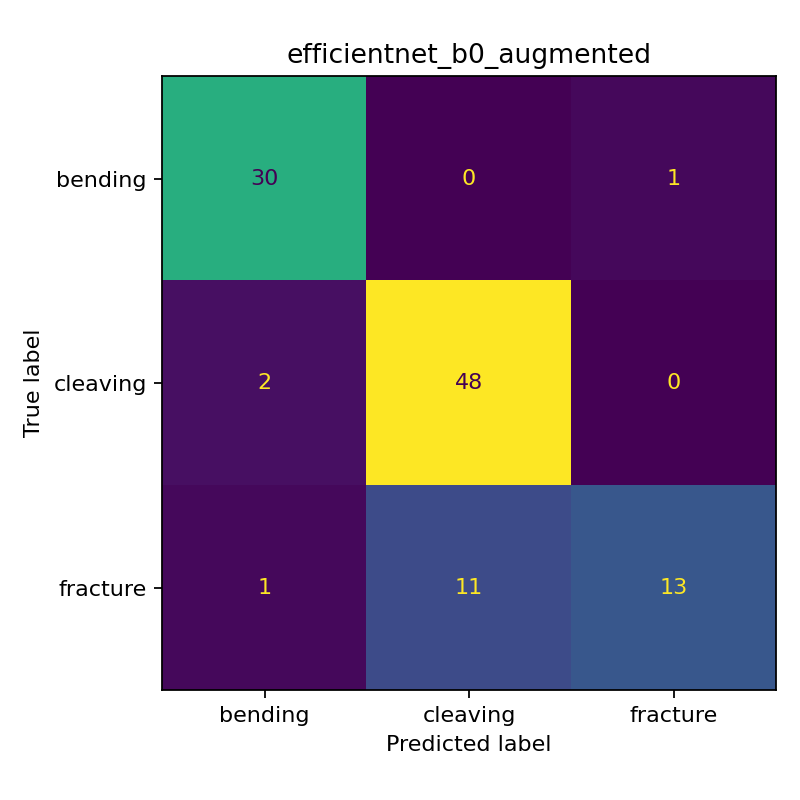

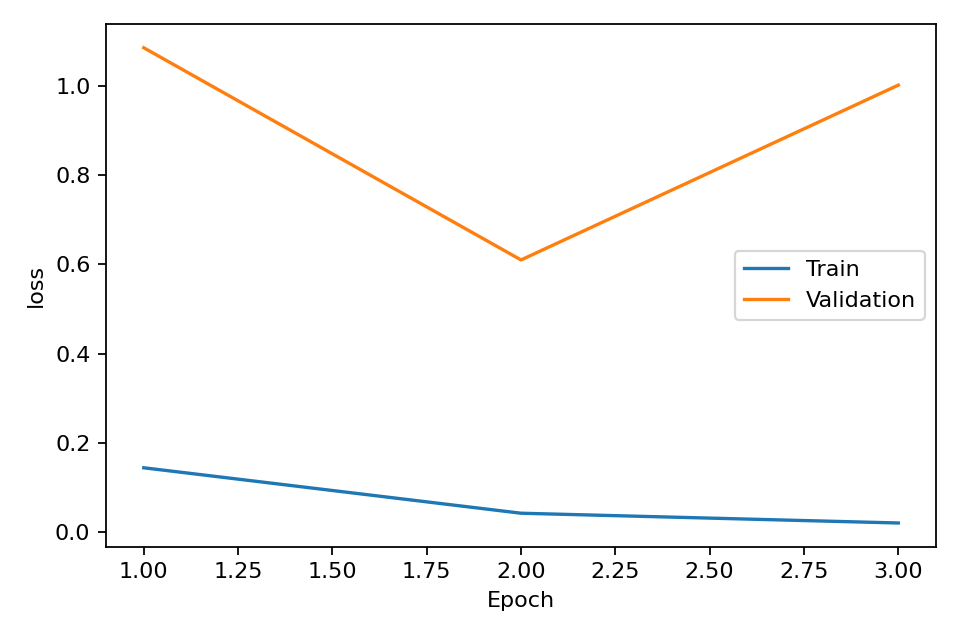

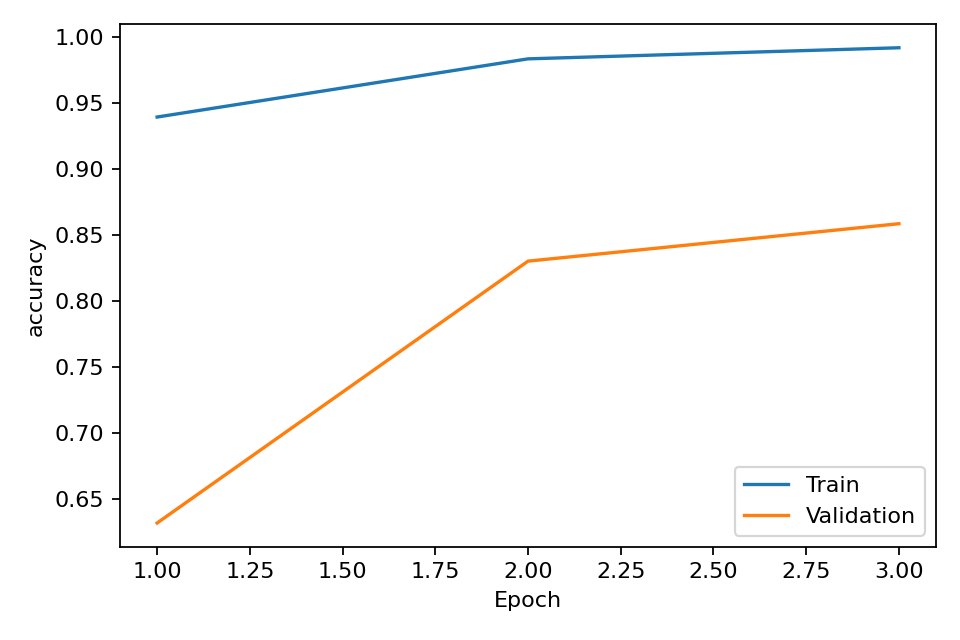

오분류 목록: /content/drive/MyDrive/SEM_CNN_Results/Fiber_Category_PNG_FolderLabels/04_Training_Reports/misclassified_images.csv


In [10]:
from IPython.display import Image as DisplayImage
display(read_csv(p.reports/'metrics.csv'))
display(read_csv(p.reports/'augmentation_effect.csv'))
display(read_csv(p.reports/'hcf_comparison.csv'))
for filename in ['confusion_matrix.png','loss_curve.png','accuracy_curve.png']:
    display(DisplayImage(filename=str(p.reports/filename)))
print('오분류 목록:', p.reports/'misclassified_images.csv')


## 4. 신규 이미지 분류·Grad-CAM·빨간 박스·Drive 저장

학습 완료 후 UI의 신규 이미지 탭에서 저장된 모델과 여러 업로드 파일을 선택하세요. 분석 후 **전체 결과 ZIP 다운로드** 버튼을 누르세요. 요청 전체를 담은 단일 한글 메모장 분석_업무보고서.txt, 요약 CSV, 분류명_연속번호.png, 빨간 박스 이미지, Grad-CAM, JSON, 원본 보존본을 ZIP으로 내려받습니다. ZIP은 알집에서 열 수 있습니다. ZIP 사본도 Drive의 05_Predictions/batch_downloads에 저장합니다. 사진별 정보바 자동 제외 후보를 지원하며, ROI·제외 영역 입력값은 선택 사진 전체에 공통 적용됩니다. 크기가 다른 사진에 공통 ROI를 지정하지 마세요. 자동 제외 후보는 전문가 확인을 대신하지 않으며 미확인 영역은 검토 필요로 기록합니다. 신규 파일에서도 ROI와 스케일바 제외를 확인합니다. 결과는 `05_Predictions`에 원본 보존본·PNG·빨간 박스 이미지·Grad-CAM·JSON으로 저장됩니다. 재실행해도 기존 번호를 이어서 사용합니다.

Grad-CAM은 모델 활성 영역이며 실제 파괴 기점이나 물리적 원인이라는 의미가 아닙니다. softmax 점수는 보정된 확률이 아닙니다. 낮은 점수·미확인 구조·품질·특징 거리 휴리스틱으로 Review Required를 표시하며 모든 미지 구조 검출을 보장하지 않습니다.


In [11]:
inference_ui = p.launch_widget_ui()


폴더명 정답 자동 적용 모드 — 사진별 수동 라벨 검토가 필요 없습니다.


In [12]:
# 실제 파일과 ROI로 바꾼 뒤 주석을 해제하면 함수로도 실행할 수 있습니다.
# prediction = p.predict('/content/new_sem.png', model_choice='selected',
#     roi='[0,0,1280,900]', masks='[]', fiber_type='HCF', region_confirmed=True)
# display(prediction[0]); display(prediction[1]); display(prediction[2]); print(prediction[3])
